# Forecasting where coding bans send a model: demo notebook

**Artifact `art_1AYTO1Epb_7t`, the iteration-3 confirmation experiment on Qwen3-8B** (bf16, Hub revision `b968826d`, thinking off), run over the 12 frozen bench tasks of exp11.

A code model asked for, say, the k-th smallest value writes the same algorithm almost every time: its **default D** (here a full sort). Tell it *"Do not use a full sort for this task."* and it has to go somewhere else. Where it goes is the ban's **landing**. The experiment asks whether that landing can be forecast **before any ban prompt is sampled**, from ban-free signals only:

| family | ban-free signal behind the forecast |
|---|---|
| **SUBTRACT** | token vetoes of the default's distinctive n-gram (vLLM `logit_bias`, exact rejection + masked redraw, coupled to neutral-twin samples): one-shot, persistent, and 3 iterated rounds |
| **LADDER** | generic pushes: a nonce ban ("the Zorblax method"), a novelty instruction, and 3 matched-norm isotropic random directions patched into the task-spec hidden states at layers 12-23 |
| **ASSOCIATE** | free-form association answers (frozen in exp11) |
| **PROXIMITY** | AST tree-edit distance (Zhang-Shasha) to the default's programs |

Every forecast was hash-chained and sealed (`commitments.log`, `SEAL_BEFORE_BANS`) before the first ban sample. Then 1,200 ban samples (12 tasks × 5 wordings W1-W5 × 20) were labelled by the gated exp11 labellers. Each family gets a **mean log score** on the ban's landing under one frozen smoothing. A frozen advance rule (**C1**) picks the winning family, and the **C2b** test asks whether a one-shot veto reproduces the ban's landing.

**What this notebook runs.** The pipeline's entry point is a stage CLI (`method.py`). Its GPU stages (vLLM sampling and HF activation patching of Qwen3-8B) need a 24 GB GPU for about 45 minutes, so they are not run here. The notebook runs the **CPU analysis path** instead ("Path A" in `reproducibility.md`), using the original code:

- `src/score.py`: the frozen scoring rules;
- `src/c2b.py`: the C2b test;
- `src/template_effect.py`: the wording effect;
- `src/analyze.py`: the committed analysis;
- `src/posthoc.py`: the post-hoc sensitivity checks;
- `src/figures_extra.py`: the extra figures;
- the pure token-veto helpers of `src/veto.py`.

The input is `mini_demo_data.json`: **100 of the 1,200 ban samples** (10 tasks × 5 templates × 2, picked to mirror each cell's label mix). Every other arm enters as its stored per-task label counts. The last cell puts the demo-scale numbers next to the stored full-run results.

**Full-run headline.**
- Only 5 of 12 bans pass the gate (T03, T06, T05, T10, T13).
- The frozen C1 rule returns `SUBTRACTION/LADDER (LADDER)` (wins: LADDER 3, PROXIMITY 2). Two of LADDER's wins, however, come from an undefined forecast scored as uniform.
- Counting defined forecasts only, no family advances, and no family beats the uniform reference on average.
- Token vetoes move the surface of the code, not the algorithm.
- Wording matters a lot (template LR 374, df 4).

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install (the original pipeline logs through it)
_pip('loguru==0.7.3')

# numpy, pandas, scipy, statsmodels, matplotlib — pre-installed on Colab, install locally only (Colab's versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'scipy==1.16.3', 'statsmodels==0.14.6', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# method.py
import subprocess
import sys
import time
from pathlib import Path

from loguru import logger

# src/common.py, score.py, c2b.py, template_effect.py, analyze.py, posthoc.py, figures_extra.py
import hashlib
import json
import math
import os
import re
import warnings
from collections import Counter
from typing import Any, Iterable

import numpy as np
import pandas as pd

# figures: the original writes PNG/PDF files under figures/ (Agg backend); the notebook shows them inline
import matplotlib
import matplotlib.pyplot as plt

# notebook: stands in for `import template_effect as TE` in analyze.py
import types

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-3/experiment-13/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            d = json.loads(response.read().decode())
        # Until this notebook's data file is pushed, the URL can still serve an older demo file of another format.
        if isinstance(d, dict) and "datasets" in d and "arm_label_counts" in d.get("metadata", {}):
            return d
        print("GitHub data is not in this notebook's format, using local mini_demo_data.json")
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
meta = data["metadata"]
examples = data["datasets"][0]["examples"]
print(f"dataset {data['datasets'][0]['dataset']!r}: {len(examples)} ban samples "
      f"(full run: {meta['n_ban_samples_full_run']}) over {len(meta['demo_tasks'])} tasks {meta['demo_tasks']}")
print("model:", meta["model"], "| decoding:", meta["decoding"])
print("metadata blocks:", [k for k in meta if k not in ("selection", "description")])

GitHub data is not in this notebook's format, using local mini_demo_data.json
dataset 'modal_ban_samples': 100 ban samples (full run: 1200) over 10 tasks ['T03', 'T04', 'T06', 'T05', 'T10', 'R1', 'T08', 'T13', 'R6', 'T11']
model: Qwen/Qwen3-8B @ b968826d (bf16) | decoding: {'temperature': 1.0, 'top_p': 1.0, 'top_k': -1, 'min_p': 0.0, 'repetition_penalty': 1.0, 'max_tokens': 1024, 'thinking': False}
metadata blocks: ['source_artifact', 'method_name', 'model', 'decoding', 'baseline_vs_method', 'predict_fields', 'commitment', 'demo_tasks', 'task_order_full', 'n_examples', 'n_ban_samples_full_run', 'per_cell', 'selection_report', 'tasks', 'forecasts', 'iterated_chain', 'arm_label_counts', 'norms_summary', 'full_run']


### What one ban sample looks like

Each example is one modal-ban sample in the artifact's `exp_gen_sol_out` format:
- `input`: the ban prompt, i.e. template + frozen task spec;
- `output`: `label|pass`;
- `predict_*`: the committed top-1 of each forecast family;
- `metadata_code`: the extracted program;
- `metadata_text`: the raw response.

The cell below prints one non-default program for each of the five tasks whose ban passes the gate. In the full run, T06 lands on `index_marking` (place each value at index value-1), a mode the model almost never writes on its own. T05 falls back to a nested-loop brute force, and T10 goes to BFS.

In [5]:
# One non-default ban sample per gated task: the ban sentence, the label from the gated labellers, the committed
# top-1 forecasts, and the first lines of the generated program.
seen = set()
for e in examples:
    t = e["metadata_task"]
    if t in ("T03", "T06", "T05", "T10", "T13") and t not in seen and e["metadata_label"] != e["metadata_banned_default"]:
        seen.add(t)
        print(f"=== {e['metadata_sample_id']} | banned default D = {e['metadata_banned_default']} | label|pass = {e['output']}")
        print("ban sentence:", e["input"].splitlines()[0])
        print("forecast top-1s:", {k[len('predict_'):]: v for k, v in e.items() if k.startswith("predict_")})
        print("\n".join(e["metadata_code"].splitlines()[:10]))
        print()

=== T03:ban:W1:0 | banned default D = full_sort | label|pass = quickselect|pass
ban sentence: Do not use a full sort for this task.
forecast top-1s: {'subtract': 'undefined', 'ladder': 'quickselect', 'associate': 'quickselect', 'proximity': 'heapify_pop'}
def solve(nums, k):
    def partition(arr, low, high):
        pivot = arr[high]
        i = low - 1
        for j in range(low, high):
            if arr[j] <= pivot:
                i += 1
                arr[i], arr[j] = arr[j], arr[i]
        arr[i+1], arr[high] = arr[high], arr[i+1]
        return i + 1

=== T06:ban:W1:0 | banned default D = hash_set | label|pass = index_marking|fail
ban sentence: Do not use a hash set of seen values for this task.
forecast top-1s: {'subtract': 'sort_adjacent', 'ladder': 'undefined', 'associate': 'floyd', 'proximity': 'sort_adjacent'}
def solve(nums):
    for i in range(len(nums)):
        current = nums[i]
        while nums[current - 1] != current:
            next_val = nums[current - 1]
     

## Configuration

Every tunable of the CPU analysis lives here.

- **`N_PER_CELL`** is the scale knob. It sets how many ban samples per (task, template) cell enter the analysis: the first `N_PER_CELL` of each cell, in file order. The mini file holds 2 per cell, and this notebook uses both. The original run had 20 (`N_BAN_PER_T`).
- **Gate threshold.** The frozen gate requires 20 non-banned attempts out of 100 ban samples per task. It is scaled with `N_PER_CELL`, and so is the C2b minimum of 10 attempts. Both equal the frozen values when `N_PER_CELL = 20`.
- **Everything else** keeps its frozen value: avoidance thresholds, smoothing, the 0.10-nat margin, and min wins 3.
- **Resampling.** The C2b null and the post-hoc bootstrap use the original 2,000 replicates.

**Full scale.** First build the full-size input in the same format, with all 1,200 ban samples:

```
python build_mini_demo_data.py --artifact-dir <artifact folder> --per-cell 20 --tasks all --out full_demo_data.json
```

Then set `data = json.loads(Path("full_demo_data.json").read_text())`, `N_PER_CELL = 20`, and `TASKS` = all 12 tasks. This reproduces the stored full-run numbers exactly, including the C1 wins, every log score, the template LR 374.1 and the placebo LR 3.7. It finishes in seconds.

In [6]:
# ---- demo configuration: every tunable of the CPU analysis ----
# Tasks whose ban samples are analysed: mini_demo_data.json holds ban samples for these 10.
# original: all 12 tasks (R3 and T14 too, only in the full-scale file)
TASKS = ["T03", "T04", "T06", "T05", "T10", "R1", "T08", "T13", "R6", "T11"]
# Ban samples per (task, template) cell: the first N_PER_CELL of each cell in file order.
# mini file: at most 2 (used here); original: N_BAN_PER_T = 20 (5 templates x 20 = 100 ban samples per task)
N_PER_CELL = 2
N_BAN_PER_T_ORIGINAL = 20
# The frozen sample-size thresholds assume 100 ban samples per task; scaled with N_PER_CELL (exact at 20)
SCALE = N_PER_CELL / N_BAN_PER_T_ORIGINAL
GATE_MIN_NON_BANNED = max(1, round(20 * SCALE))  # frozen: >= 20 non-banned attempts for a gated event
C2B_MIN_ATTEMPTS = max(1, round(10 * SCALE))     # frozen: >= 10 attempts in S' for a C2b-eligible event
C2B_NULL_REPLICATES = 2000                       # frozen: 2000 template-resampling null replicates
POSTHOC_N_BOOT = 2000                            # original: 2000 task-cluster bootstrap replicates

print(f"N_PER_CELL = {N_PER_CELL} -> {5 * N_PER_CELL} ban samples per task; gate needs >= {GATE_MIN_NON_BANNED} "
      f"non-banned attempts; C2b needs >= {C2B_MIN_ATTEMPTS}; null replicates {C2B_NULL_REPLICATES}; "
      f"bootstrap {POSTHOC_N_BOOT}")

N_PER_CELL = 2 -> 10 ban samples per task; gate needs >= 2 non-banned attempts; C2b needs >= 1; null replicates 2000; bootstrap 2000


## 1. `method.py`: the pipeline entry point

`method.py` runs the pipeline stage by stage. Every GPU stage is a separate Python process, so GPU memory is released when it exits:

- **A**: vLLM ban-free arms;
- **B**: HF norms and random directions;
- **C**: vLLM modal bans;
- **D**: HF band-patch control;
- **D2**: HF fp32 FRLP rescoring.

The `commit` stage seals the hash chain (`SEAL_BEFORE_BANS`), and stage C refuses to run without a valid seal. So no ban prompt is ever sampled before the forecasts are frozen.

The code is copied unchanged, except that `ROOT` cannot come from `__file__` in a notebook. Calling `main()` with `--help` prints the stage table. The stages themselves need `src/`, the bench inputs, Qwen3-8B and a GPU. The CPU stages `analyze`, `posthoc` and `figures` are re-run in the cells below from `mini_demo_data.json`.

In [7]:
__doc__ = """Predicting where coding bans send a model (iteration 3): entry point.

Runs the pipeline stage by stage.  Every GPU stage is a separate Python process so GPU memory is released at exit
(A: vLLM ban-free arms; B: HF norms + random directions; C: vLLM modal bans; D: HF band-patch control; D2: HF fp32
FRLP rescoring).  No modal-ban prompt is sampled before the 'commit' stage seals the hash chain; stage C refuses to
run without a valid SEAL_BEFORE_BANS line.

    .venv/bin/python method.py all            # the full pipeline, in order
    .venv/bin/python method.py <stage> ...    # one or more stages (see STAGES)
"""

ROOT = Path.cwd()  # notebook: no __file__ here; the original is Path(__file__).resolve().parent
PY = sys.executable
SRC = ROOT / "src"

# stage -> (script relative to the repo, arguments, what it does)
STAGES: dict[str, tuple[str, list[str], str]] = {
    "setup": ("src/setup_inputs.py", [], "S0.1-0.2 copy + verify the frozen bench, provenance commit, env.json"),
    "recheck": ("src/labelpool.py", [], "S0.3 labeller re-check on gold sets and references vs gate.json"),
    "prompts": ("src/prompts.py", [], "S0.4 ban / twin / nonce / novelty prompts, token alignment, spec spans"),
    "ngrams": ("src/ngrams.py", [], "S0.5 distinctive + sham n-grams (FP8 pilot), unit tests"),
    "proximity": ("src/proximity.py", [], "S0.6 AST tree-edit-distance PROXIMITY nominees"),
    "nominees": ("src/forecasts.py", ["nominees"], "S0.7-0.8 ASSOCIATE and FRLP_FP8 nominees"),
    "gen_a": ("src/vllm_stage.py", ["A"], "S1 GPU process A: twin, vetoes, nonce, novelty, iterated rounds"),
    "hf_b": ("src/hf_stage.py", ["B"], "S1.7 GPU process B: norms, random directions, HF twin control"),
    "forecasts": ("src/forecasts.py", ["build"], "S1d ban-free forecasts"),
    "commit": ("src/forecasts.py", ["commit"], "S1d hash-chained commitment + SEAL_BEFORE_BANS"),
    "gen_c": ("src/vllm_stage.py", ["C"], "S2 GPU process C: modal bans (guarded)"),
    "hf_d": ("src/hf_stage.py", ["D"], "S2b(i) GPU process D: band-patch positive control"),
    "frlp": ("src/frlp_rescore.py", [], "S2b(ii) fp32 FRLP rescoring (descriptive)"),
    "analyze": ("src/analyze.py", [], "S3 committed analysis: C1, C2b, descriptives, template effect, figures"),
    "posthoc": ("src/posthoc.py", [], "post-hoc (not pre-registered) sensitivity analyses"),
    "sanity": ("src/sanity.py", [], "T9 post-run sanity checks"),
    "figures": ("src/figures_extra.py", [], "extra figures (redrawn log-score plot, forecast table)"),
    "outputs": ("src/outputs.py", [], "data/samples.jsonl + method_out.json"),
    "audit": ("audit/rederive.py", [], "independent re-derivation + placebos"),
}
ORDER = ["setup", "recheck", "prompts", "ngrams", "proximity", "nominees", "gen_a", "hf_b", "forecasts", "commit",
         "gen_c", "hf_d", "frlp", "analyze", "posthoc", "sanity", "figures", "outputs", "audit"]


def run_stage(name: str) -> None:
    script, args, what = STAGES[name]
    cwd = ROOT / Path(script).parent
    logger.info(f"=== stage {name}: {what}")
    t0 = time.time()
    r = subprocess.run([PY, str(ROOT / script), *args], cwd=cwd)
    if r.returncode != 0:
        raise SystemExit(f"stage {name} failed with exit code {r.returncode}")
    logger.info(f"=== stage {name} done in {time.time() - t0:.0f}s")


@logger.catch(reraise=True)
def main() -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    (ROOT / "logs").mkdir(exist_ok=True)
    logger.add(str(ROOT / "logs" / "method.log"), rotation="30 MB", level="DEBUG")
    names = sys.argv[1:] or ["--help"]
    if names[0] in ("-h", "--help"):
        print(__doc__)
        for n in ORDER:
            print(f"  {n:<10} {STAGES[n][2]}")
        return
    if names == ["all"]:
        names = ORDER
    for n in names:
        if n not in STAGES:
            raise SystemExit(f"unknown stage {n!r}; choose from {', '.join(ORDER)} or 'all'")
        run_stage(n)


# notebook: `python method.py --help` (the kernel's own argv would be read as stage names)
_argv, sys.argv = sys.argv, ["method.py", "--help"]
main()
sys.argv = _argv

Predicting where coding bans send a model (iteration 3): entry point.

Runs the pipeline stage by stage.  Every GPU stage is a separate Python process so GPU memory is released at exit
(A: vLLM ban-free arms; B: HF norms + random directions; C: vLLM modal bans; D: HF band-patch control; D2: HF fp32
FRLP rescoring).  No modal-ban prompt is sampled before the 'commit' stage seals the hash chain; stage C refuses to
run without a valid SEAL_BEFORE_BANS line.

    .venv/bin/python method.py all            # the full pipeline, in order
    .venv/bin/python method.py <stage> ...    # one or more stages (see STAGES)

  setup      S0.1-0.2 copy + verify the frozen bench, provenance commit, env.json
  recheck    S0.3 labeller re-check on gold sets and references vs gate.json
  prompts    S0.4 ban / twin / nonce / novelty prompts, token alignment, spec spans
  ngrams     S0.5 distinctive + sham n-grams (FP8 pilot), unit tests
  proximity  S0.6 AST tree-edit-distance PROXIMITY nominees
  nominees 

## 2. `src/common.py`: constants every stage agrees on

This module holds the model and its revision, the task order and the default (modal) mode D of every task, the frozen W1-W5 ban/neutral templates, the decoding settings, the layer band, the seed rule, and the **frozen analysis constants**:

- the gate;
- the forecast smoothing `0.93·p_raw + 0.05·Uniform(S) + 0.02·δ_other`;
- the advance rule (win margin 0.10 nats, at least 3 wins);
- the C2b settings.

Two lines differ from the original. `TASK_ORDER` is restricted to the configured tasks, and the two sample-size thresholds come from the config cell. The bench lookups (`spec`, `catalogue`, `survivors`, `display_name`) read the frozen `spec.json` catalogues shipped inside the mini file instead of `inputs/bench/`. The file-I/O, logging and GPU helpers of `common.py` are omitted, since nothing is read from or written to disk here.

The check at the end confirms two things about the stored data. The per-request seed rule reproduces the seed stored with a sample. And the stored ban prompt is exactly `cap_first(template) + blank line + frozen spec` (`src/prompts.py`).

In [8]:
MODEL_ID = "Qwen/Qwen3-8B"
REVISION = "b968826d9c46dd6066d109eabc6255188de91218"

# Stage-A order (exp11 commitments.log, stageA_order, R2 excluded by the 12-task freeze cap)
TASK_ORDER = ["T03", "T04", "T06", "T05", "T10", "R1", "T08", "R3", "T13", "R6", "T14", "T11"]
TASK_ORDER = [t for t in TASK_ORDER if t in TASKS]  # notebook: only the tasks chosen in the config cell
# The default D of every task = the modal label of the exp11 FP8 pilot (protocol table); checked against pilot_rows.
DEFAULTS = {"T03": "full_sort", "T04": "naive", "T06": "hash_set", "T05": "hash_map", "T10": "union_find",
            "R1": "greedy_end", "T08": "iteration", "R3": "kahn", "T13": "sort_sweep", "R6": "binary_search",
            "T14": "sort_by_count", "T11": "quadratic_dp"}

WS = ["W1", "W2", "W3", "W4", "W5"]
# W1-W5 (ban, neutral) verbatim from the shared protocol (exp7 src/config.py, exp8 cfg.py).
TEMPLATES = {
    "W1": ("Do not use {X} for this task.", "Do not use {N} for this task."),
    "W2": ("Your solution must not rely on {X}.", "Your solution must not rely on {N}."),
    "W3": ("Avoid {X} entirely.", "Avoid {N} entirely."),
    "W4": ("{X} is not allowed here.", "{N} is not allowed here."),
    "W5": ("Write a correct solution that does not use {X}.", "Write a correct solution that does not use {N}."),
}
NONCE_X = "the Zorblax method"
NOVELTY = "Write a novel algorithm for this task, one you have not seen before."
FILLER = " ."
NOUN_EXCLUSIONS = {"ass", "bucket", "chain", "edge", "game", "graph", "grid", "head", "heap", "key", "line", "link",
                   "list", "map", "maze", "net", "node", "path", "point", "queue", "ring", "road", "route", "search",
                   "stack", "step", "street", "table", "track", "train", "tree", "walk", "way", "web"}

MAX_NEW = 1024
DECODING = {"temperature": 1.0, "top_p": 1.0, "top_k": -1, "min_p": 0.0, "repetition_penalty": 1.0,
            "max_tokens": MAX_NEW, "thinking": False}
BAND = list(range(12, 24))  # layers 12-23 (0-indexed decoder layers); output of layer l = hidden_states[l + 1]
N_RAND_DIRS = 3
IM_END = 151645
ENDOFTEXT = 151643
EOS_IDS = (IM_END, ENDOFTEXT)
FENCE_OPEN = "```python\n"
FENCE_CLOSE = "```"
CHAT_TAIL = "<|im_start|>assistant\n<think>\n\n</think>\n\n"

# Sample sizes (plan): twin 5x10, nonce 5x10, novelty 50, random directions 3 x 50 (5x10), bans 5x20.
N_TWIN_PER_T = 10
N_NONCE_PER_T = 10
N_NOVELTY = 50
N_RAND_PER_T = 10
N_BAN_PER_T = 20
N_HF_TWIN_PER_T = 10
N_BANDPATCH_PER_T = 10

FROZEN_CONSTANTS = {
    # notebook: min_non_banned_attempts (frozen 20) is scaled with N_PER_CELL, see the config cell
    "gate": {"min_avoidance": 0.5, "min_non_banned_attempts": GATE_MIN_NON_BANNED},
    "forecast_min_non_default": 20,
    "smoothing": {"raw": 0.93, "uniform_survivors": 0.05, "other": 0.02},
    "advance": {"margin_nats": 0.10, "min_wins": 3},
    "wilcoxon_min_events": 10,
    # notebook: min_attempts_in_S_prime (frozen 10) and null_replicates (frozen 2000) come from the config cell
    "c2b": {"min_one_shot_avoidance": 0.5, "min_attempts_in_S_prime": C2B_MIN_ATTEMPTS, "confirm_share": 2 / 3,
            "elsewhere_share": 1 / 3, "null_replicates": C2B_NULL_REPLICATES, "null_seed": 20261021,
            "null_quantile": 0.95, "min_eligible_events": 3},
    "iterated": {"trigger_default_share": 0.20, "max_rounds": 3, "coverage": 0.8, "max_greedy_ngrams": 3},
    "ngram": {"n_max": 6, "coverage": 0.8, "co_veto_collateral": 0.5},
    "veto_cap": 32,
    "ladder_exists_min_pushes": 2,
    "unaimed_share": 0.5,
    "tie_rules": "top-1: argmax over S of p_raw, ties to catalogue order (flagged); n-gram: min max-collateral, then "
                 "smaller n, higher coverage, lexicographically smallest id tuple",
}


def canon(obj: Any) -> str:
    return json.dumps(obj, sort_keys=True, separators=(",", ":"), ensure_ascii=False)


def stable_seed(*parts: Any) -> int:
    """Per-request seed = int(sha256('iter3|exp|task|arm|template|idx')[:8], 16)."""
    key = "iter3|exp|" + "|".join(str(p) for p in parts)
    return int(hashlib.sha256(key.encode()).hexdigest()[:8], 16)


def spec(task: str) -> dict:
    # notebook: the frozen bench spec.json (inputs/bench/<task_id>/spec.json), shipped inside mini_demo_data.json
    return data["metadata"]["tasks"][task]


def catalogue(task: str) -> list[str]:
    return [c["mode"] for c in spec(task)["catalogue"]]


def survivors(task: str) -> list[str]:
    return [m for m in catalogue(task) if m != DEFAULTS[task]]


def display_name(task: str, mode: str) -> str:
    for c in spec(task)["catalogue"]:
        if c["mode"] == mode:
            return c["display_name"]
    raise KeyError((task, mode))


def cap_first(s: str) -> str:
    return s[:1].upper() + s[1:] if s else s


# notebook check: the seed rule and the ban-prompt rule (src/prompts.py) reproduce the stored samples
for e in examples[:3]:
    t, w, i = e["metadata_task"], e["metadata_template"], int(e["metadata_sample_id"].split(":")[-1])
    ban_text = cap_first(TEMPLATES[w][0].format(X=display_name(t, DEFAULTS[t]))) + "\n\n" + spec(t)["spec_text"]
    print(f"{e['metadata_sample_id']}: stored seed == stable_seed: {stable_seed(t, 'ban', w, i) == e['metadata_seed']}; "
          f"stored prompt == template + spec: {ban_text == e['input']}")
t = TASK_ORDER[0]
print(f"\n{t}: D = {DEFAULTS[t]} ({display_name(t, DEFAULTS[t])!r}); survivors S = {survivors(t)}")
for w in WS:
    print(f"  {w}: {cap_first(TEMPLATES[w][0].format(X=display_name(t, DEFAULTS[t])))}")

T03:ban:W1:0: stored seed == stable_seed: True; stored prompt == template + spec: True
T03:ban:W1:1: stored seed == stable_seed: True; stored prompt == template + spec: True
T03:ban:W2:0: stored seed == stable_seed: True; stored prompt == template + spec: True

T03: D = full_sort ('a full sort'); survivors S = ['size_k_heap', 'heapify_pop', 'quickselect', 'median_of_medians', 'counting_sort']
  W1: Do not use a full sort for this task.
  W2: Your solution must not rely on a full sort.
  W3: Avoid a full sort entirely.
  W4: A full sort is not allowed here.
  W5: Write a correct solution that does not use a full sort.


## 3. `src/veto.py`: the coupled token-veto engine behind SUBTRACT

The SUBTRACT forecast asks what happens if the default's most distinctive token n-gram becomes impossible, with no named ban in the prompt.

**How a veto arm is sampled.**
1. Each veto arm starts from a neutral-twin sample with the same seed.
2. At the first position where the generation completes a masked n-gram, that draw is rejected.
3. The token is redrawn from the masked conditional: every completing token gets vLLM `logit_bias = -100`.
4. The rest of the sample is generated afresh.

Rejection plus masked redraw yields exactly the masked conditional at every position, and the arms stay paired by seed. **One-shot** vetoes only the first completion. **Persistent** vetoes every completion. **Iterated** rounds re-derive a new n-gram from the programs that still implement D.

The sampling loop `run_veto` drives vLLM on a GPU, so it is not run here. The pure helpers below are the original code, applied to toy token ids:
- T05's distinctive n-gram `' if complement'` is the id pair (421, 22766);
- after the token `' if'` the engine bans `' complement'`.

The printout of the stored iterated chain shows the main finding: the model **re-spells** the same mechanism instead of changing algorithm. On T05, round 1's new distinctive token is the misspelling `' compliment'`. Later rounds veto loop indices and comment words.

In [9]:
VETO_CAP = 32


def banned_after(prefix: list[int], mask: list[tuple[int, ...]]) -> set[int]:
    out = set()
    L = len(prefix)
    for g in mask:
        n = len(g)
        if n == 1 or (L >= n - 1 and tuple(prefix[L - n + 1:]) == g[:-1]):
            out.add(g[-1])
    return out


def find_completion(gen: list[int], start: int, mask: list[tuple[int, ...]]) -> int | None:
    """First position t >= start where gen[t] completes some g in mask (gen[:t] ends in g[:-1])."""
    last = {}
    for g in mask:
        last.setdefault(g[-1], []).append(g)
    for t in range(start, len(gen)):
        tok = gen[t]
        if tok in EOS_IDS:
            return None
        for g in last.get(tok, ()):
            n = len(g)
            if t >= n - 1 and tuple(gen[t - n + 1:t]) == g[:-1]:
                return t
    return None


def count_occurrences(gen: list[int], g: tuple[int, ...]) -> int:
    n = len(g)
    return sum(1 for i in range(len(gen) - n + 1) if tuple(gen[i:i + n]) == g)


def strip_eos(ids: list[int]) -> list[int]:
    out = list(ids)
    while out and out[-1] in EOS_IDS:
        out.pop()
    return out


def veto_seed(seed: int, rnd: int, n_vetoes: int, tag: str) -> int:
    return stable_seed("veto", seed, rnd, n_vetoes, tag)


# notebook: the helpers on toy token ids (T05's distinctive n-gram ' if complement' = ids 421, 22766)
mask = [(421, 22766)]
gen = [10, 421, 5, 421, 22766, 7, 421, 22766, IM_END]
print("tokens banned after a prefix ending in ' if':", banned_after(gen[:4], mask))
print("tokens banned after any other prefix        :", banned_after(gen[:3], mask))
print("first completing position (where a one-shot veto redraws):", find_completion(gen, 0, mask),
      "| completions in the sample:", count_occurrences(gen, (421, 22766)), "| EOS stripped:", strip_eos(gen)[-2:])
print("seed of the masked redraw for sample seed 913467122, round 0, first veto:", veto_seed(913467122, 0, 0, "r"))
print("\nvetoed n-gram texts per chain round (predictions/ngrams.json + iterated_chain.json):")
for t in TASK_ORDER:
    ch = meta["iterated_chain"][t]
    print(f"  {t:>4} D={DEFAULTS[t]:<14} {ch['vetoed_texts_by_round']}")

tokens banned after a prefix ending in ' if': {22766}
tokens banned after any other prefix        : set()
first completing position (where a one-shot veto redraws): 4 | completions in the sample: 2 | EOS stripped: [421, 22766]
seed of the masked redraw for sample seed 913467122, round 0, first veto: 3074163748

vetoed n-gram texts per chain round (predictions/ngrams.json + iterated_chain.json):
   T03 D=full_sort      {'round0': ['    nums'], 'round1': ['k-'], 'round2': ['k -'], 'round3': [')[k']}
   T04 D=naive          {'round0': [' needle:\n           '], 'round1': ['1\n    \n    for'], 'round2': ['        if haystack[i:i'], 'round3': ['i']}
   T06 D=hash_set       {'round0': [' set'], 'round1': [' seen']}
   T05 D=hash_map       {'round0': [' if complement'], 'round1': [' compliment'], 'round2': [' i]\n'], 'round3': [' < i']}
   T10 D=union_find     {'round0': [' find'], 'round1': [' parent']}
    R1 D=greedy_end     {'round0': [' if start'], 'round1': [' = end'], 'round2': ['    \

## 4. `src/score.py`: the frozen scoring rules (committed before the first ban sample)

**Outcome space.** The outcome space of a modal-ban event is `S` = the task's catalogue minus the banned default D, plus `'other'`.

**Forecasts.** Every family's forecast `p_raw` is smoothed by one rule: `0.93·p_raw + 0.05·Uniform(S) + 0.02·δ_other`.
- Point forecasts are delta masses.
- An **undefined** forecast is scored as uniform. This detail matters later.

**Scoring.** The **log score** of a family is the mean of `ln p(label)` over the ban's non-banned attempted programs.

**Advance rule.** A family **wins** an event if its log score beats every other family's by at least 0.10 nats. A family **advances** with at least 3 wins.

The file's unit tests run first.

In [10]:
SMOOTH_RAW, SMOOTH_UNIF, SMOOTH_OTHER = 0.93, 0.05, 0.02
PRIMARY = ["SUBTRACT", "LADDER", "ASSOCIATE", "PROXIMITY"]
DESCRIPTIVE = ["SUBTRACT_1SHOT", "FRLP_FP8", "UNIFORM"]


def space(S: list[str]) -> list[str]:
    return list(S) + ["other"]


def p_from_counts(counts: dict[str, float], S: list[str]) -> dict[str, float] | None:
    """Normalise landing counts over S plus 'other' (labels outside the space are ignored); None if empty."""
    tot = sum(v for k, v in counts.items() if k in S or k == "other")
    if tot <= 0:
        return None
    return {k: counts.get(k, 0) / tot for k in space(S)}


def p_point(nominee: str | None, S: list[str]) -> dict[str, float] | None:
    if nominee is None or nominee not in S:
        return None
    return {k: float(k == nominee) for k in space(S)}


def p_uniform(S: list[str]) -> dict[str, float]:
    return {k: (1.0 / len(S) if k in S else 0.0) for k in space(S)}


def smooth(p_raw: dict[str, float] | None, S: list[str]) -> dict[str, float]:
    raw = p_raw if p_raw is not None else p_uniform(S)
    out = {}
    for k in space(S):
        out[k] = SMOOTH_RAW * raw.get(k, 0.0) + SMOOTH_UNIF * (1.0 / len(S) if k in S else 0.0) + \
            SMOOTH_OTHER * (1.0 if k == "other" else 0.0)
    return out


def top1(p_raw: dict[str, float] | None, S: list[str]) -> tuple[str | None, bool]:
    """argmax over S of p_raw; ties -> first in catalogue order (S is in catalogue order); returns (top1, tie_flag)."""
    if p_raw is None:
        return None, False
    best = max(p_raw.get(k, 0.0) for k in S)
    if best <= 0:
        return None, False
    tied = [k for k in S if abs(p_raw.get(k, 0.0) - best) < 1e-12]
    return tied[0], len(tied) > 1


def logscore(p: dict[str, float], labels: list[str]) -> float:
    if not labels:
        return float("nan")
    return sum(math.log(p[l]) for l in labels) / len(labels)


def realised_top1(labels: list[str], S: list[str]) -> list[str]:
    """Modal label over S plus 'other' (all tied labels listed)."""
    c = Counter(l for l in labels if l in S or l == "other")
    if not c:
        return []
    m = max(c.values())
    return [k for k in space(S) if c.get(k, 0) == m]


def hill1(labels: list[str]) -> float:
    c = Counter(labels)
    n = sum(c.values())
    if n == 0:
        return float("nan")
    return math.exp(-sum((v / n) * math.log(v / n) for v in c.values()))


def wilson(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def js_divergence(p: dict[str, float], q: dict[str, float]) -> float:
    """Jensen-Shannon divergence, base 2."""
    keys = set(p) | set(q)
    m = {k: 0.5 * (p.get(k, 0.0) + q.get(k, 0.0)) for k in keys}

    def kl(a):
        return sum(a[k] * math.log2(a[k] / m[k]) for k in keys if a.get(k, 0.0) > 0)

    return 0.5 * kl({k: p.get(k, 0.0) for k in keys}) + 0.5 * kl({k: q.get(k, 0.0) for k in keys})


def advance(events: list[dict[str, Any]], families: list[str], margin: float = 0.10, min_wins: int = 3
            ) -> dict[str, Any]:
    """Family F wins an event if LS_F - max over the other families of LS >= margin; F advances with >= min_wins."""
    wins = {f: 0 for f in families}
    per_event = []
    for e in events:
        ls = e["logscore"]
        w = None
        for f in families:
            others = [ls[g] for g in families if g != f]
            if others and ls[f] - max(others) >= margin:
                wins[f] += 1
                w = f
        per_event.append({"task": e["task"], "winner": w})
    return {"wins": wins, "advancing": [f for f in families if wins[f] >= min_wins], "per_event": per_event}


def unit_tests() -> dict[str, bool]:
    S = ["a", "b", "c"]
    res = {}
    true = {"a": 0.7, "b": 0.2, "c": 0.1, "other": 0.0}
    labels = ["a"] * 7 + ["b"] * 2 + ["c"]
    res["true_beats_uniform"] = logscore(smooth(true, S), labels) > logscore(smooth(None, S), labels)
    for pr in [true, None, p_point("b", S), p_from_counts({"a": 3, "other": 1}, S)]:
        p = smooth(pr, S)
        res.setdefault("sums_to_one", True)
        res["sums_to_one"] &= abs(sum(p.values()) - 1) < 1e-12
        res.setdefault("other_at_least_002", True)
        res["other_at_least_002"] &= p["other"] >= 0.02 - 1e-12
    res["undefined_is_uniform"] = smooth(None, S) == smooth(p_uniform(S), S)
    res["tie_to_catalogue_order"] = top1({"a": 0.4, "b": 0.4, "c": 0.2, "other": 0}, S) == ("a", True)
    res["top1_ignores_other"] = top1({"a": 0.1, "b": 0.2, "c": 0.0, "other": 0.7}, S) == ("b", False)
    ev = [{"task": "x", "logscore": {"F": -0.1, "G": -0.5}}, {"task": "y", "logscore": {"F": -0.1, "G": -0.15}},
          {"task": "z", "logscore": {"F": -0.2, "G": -0.6}}, {"task": "w", "logscore": {"F": -0.2, "G": -0.6}}]
    a = advance(ev, ["F", "G"])
    res["advance_counts"] = a["wins"] == {"F": 3, "G": 0} and a["advancing"] == ["F"]
    res["js_zero_identical"] = abs(js_divergence({"a": 0.5, "b": 0.5}, {"a": 0.5, "b": 0.5})) < 1e-12
    res["js_one_disjoint"] = abs(js_divergence({"a": 1.0}, {"b": 1.0}) - 1.0) < 1e-12
    res["all_pass"] = all(res.values())
    return res


print("score.py unit tests:", unit_tests())

score.py unit tests: {'true_beats_uniform': True, 'sums_to_one': True, 'other_at_least_002': True, 'undefined_is_uniform': True, 'tie_to_catalogue_order': True, 'top1_ignores_other': True, 'advance_counts': True, 'js_zero_identical': True, 'js_one_disjoint': True, 'all_pass': True}


## 5. `src/c2b.py`: does the one-shot veto reproduce the ban's landing?

**Question.** C2b compares the landing of the **one-shot token veto** (no ban in the prompt) with the landing of the **named ban**, over `S'` = S minus any co-vetoed survivors, plus `'other'`.

**Eligibility.** An event needs a gated ban, one-shot avoidance of at least 0.5, and at least 10 attempts in `S'` on both sides.

**Per-event test.**
- The two modal survivors are compared.
- The Jensen-Shannon divergence (base 2) between the landings is tested against a **template-resampling null**: 2,000 two-stage bootstrap pseudo-landings drawn from the ban's own attempts.
- **REPRODUCES** = same modal survivor and JS ≤ null p95. **LANDS ELSEWHERE** = the modal survivor differs.

**Verdict.** CONFIRMED / DISCONFIRMED / BOUNDARY / INCONCLUSIVE, or UNDETERMINED with fewer than 3 eligible events.

The original's `from score import js_divergence` is not needed in the notebook, because `score.py` is already defined above.

In [11]:
def dist(labels: list[str], space: list[str]) -> dict[str, float]:
    c = Counter(l for l in labels if l in space)
    n = sum(c.values())
    return {k: c.get(k, 0) / n for k in space} if n else {k: 0.0 for k in space}


def modal(labels: list[str], space: list[str]) -> tuple[str | None, bool]:
    c = Counter(l for l in labels if l in space)
    if not c:
        return None, False
    m = max(c.values())
    tied = [k for k in space if c.get(k, 0) == m]
    return tied[0], len(tied) > 1


def pseudo_landing(rng: np.random.Generator, by_t: dict[str, list[str]], m: int) -> list[str]:
    temps = sorted(w for w, v in by_t.items() if v)
    slots = rng.choice(len(temps), size=5, replace=True)
    sizes = np.full(5, m // 5)
    rem = m % 5
    if rem:
        sizes[rng.choice(5, size=rem, replace=False)] += 1
    out: list[str] = []
    for s, k in zip(slots, sizes):
        pool = by_t[temps[s]]
        if k:
            out += [pool[i] for i in rng.integers(0, len(pool), size=int(k))]
    return out


def null_p95(by_t: dict[str, list[str]], n_veto: int, n_ban: int, space: list[str], seed: int, reps: int = 2000,
             q: float = 0.95) -> tuple[float, np.ndarray]:
    rng = np.random.default_rng(seed)
    vals = np.empty(reps)
    for i in range(reps):
        a = pseudo_landing(rng, by_t, n_veto)
        b = pseudo_landing(rng, by_t, n_ban)
        vals[i] = js_divergence(dist(a, space), dist(b, space))
    return float(np.quantile(vals, q)), vals


def event_seed(base: int, task: str, tag: str) -> int:
    return int(hashlib.sha256(f"{base}|{task}|{tag}".encode()).hexdigest()[:8], 16)


def c2b_event(task: str, veto_labels: list[str], ban_by_template: dict[str, list[str]], space: list[str],
              seed: int, reps: int = 2000) -> dict[str, Any]:
    """veto_labels / ban_by_template: non-banned attempted labels already mapped into S plus 'other'."""
    v = [l for l in veto_labels if l in space]
    bt = {w: [l for l in ls if l in space] for w, ls in ban_by_template.items()}
    b = [l for ls in bt.values() for l in ls]
    mv, tv = modal(v, space)
    mb, tb = modal(b, space)
    js = js_divergence(dist(v, space), dist(b, space))
    p95, _ = null_p95(bt, len(v), len(b), space, seed, reps)
    agree = mv is not None and mv == mb
    return {"task": task, "n_veto": len(v), "n_ban": len(b), "modal_veto": mv, "modal_ban": mb,
            "modal_tie_veto": tv, "modal_tie_ban": tb, "agree": agree, "js": js, "null_p95": p95,
            "reproduces": bool(agree and js <= p95), "elsewhere": bool(not agree),
            "veto_landing": dict(Counter(v)), "ban_landing": dict(Counter(b))}


def verdict(events: list[dict[str, Any]], min_events: int = 3, confirm: float = 2 / 3,
            elsewhere: float = 1 / 3) -> dict[str, Any]:
    n = len(events)
    if n < min_events:
        return {"verdict": "UNDETERMINED", "n_eligible": n}
    rep = sum(e["reproduces"] for e in events) / n
    els = sum(e["elsewhere"] for e in events) / n
    c_bar = rep >= confirm - 1e-12
    d_bar = els >= elsewhere - 1e-12
    if c_bar and d_bar:
        v = "BOUNDARY"
    elif c_bar:
        v = "CONFIRMED"
    elif d_bar:
        v = "DISCONFIRMED"
    else:
        v = "INCONCLUSIVE"
    return {"verdict": v, "n_eligible": n, "share_reproducing": rep, "share_elsewhere": els}


def unit_tests() -> dict[str, bool]:
    res = {}
    sp = ["a", "b", "other"]
    by_t = {w: ["a"] * 8 + ["b"] * 2 for w in ["W1", "W2", "W3", "W4", "W5"]}
    p1, _ = null_p95(by_t, 30, 60, sp, 7, reps=300)
    p2, _ = null_p95(by_t, 30, 60, sp, 7, reps=300)
    res["null_reproducible"] = p1 == p2
    e_same = c2b_event("x", ["a"] * 25 + ["b"] * 5, by_t, sp, 1, reps=300)
    res["reproduces_when_same"] = e_same["reproduces"]
    e_diff = c2b_event("y", ["b"] * 30, by_t, sp, 2, reps=300)
    res["elsewhere_when_different"] = e_diff["elsewhere"]
    mk = lambda r, e: {"reproduces": r, "elsewhere": e}
    res["confirmed"] = verdict([mk(True, False)] * 3)["verdict"] == "CONFIRMED"
    res["disconfirmed"] = verdict([mk(False, True)] * 2 + [mk(True, False)])["verdict"] == "DISCONFIRMED"
    res["boundary"] = verdict([mk(True, False)] * 2 + [mk(False, True)])["verdict"] == "BOUNDARY"
    res["inconclusive"] = verdict([mk(False, False)] * 2 + [mk(True, False)])["verdict"] == "INCONCLUSIVE"
    res["undetermined"] = verdict([mk(True, False)] * 2)["verdict"] == "UNDETERMINED"
    res["all_pass"] = all(res.values())
    return res


print("c2b.py unit tests:", unit_tests())
c2b_verdict = verdict  # notebook: analyze.py imports it as `from c2b import verdict as c2b_verdict`

c2b.py unit tests: {'null_reproducible': True, 'reproduces_when_same': True, 'elsewhere_when_different': True, 'confirmed': True, 'disconfirmed': True, 'boundary': True, 'inconclusive': True, 'undetermined': True, 'all_pass': True}


## 6. `src/template_effect.py`: does the wording of the ban matter?

The outcome is `banned = 1` when an attempted program still implements the banned default D. The module reports four things:

- the per-template banned share per task, with Wilson 95% intervals;
- a pooled statsmodels `BinomialBayesMixedGLM`: task fixed effects plus random template and template×task intercepts, fitted by variational Bayes;
- a fixed-effects logistic **likelihood-ratio test** of template (df = 4). Tasks whose banned indicator is constant are dropped, because they separate perfectly;
- a **placebo**: template labels shuffled within task, which should show no effect.

In the full run the effect is strong (LR 374, p ≈ 1e-79, placebo p 0.44). Under W4 ("X is not allowed here.") the default survives on 10 of 12 tasks.

In [12]:
def frame(rows: list[dict], defaults: dict[str, str]) -> pd.DataFrame:
    recs = [{"task": r["task"], "template": r["template"], "banned": int(r["label"] == defaults[r["task"]])}
            for r in rows if r["label"] != "invalid"]
    return pd.DataFrame(recs)


def per_template(df: pd.DataFrame) -> dict[str, Any]:
    out = {}
    for (t, w), g in df.groupby(["task", "template"]):
        k, n = int(g["banned"].sum()), len(g)
        lo, hi = wilson(k, n)
        out.setdefault(t, {})[w] = {"k": k, "n": n, "share": k / n if n else None, "wilson95": [lo, hi]}
    return out


def lr_test(df: pd.DataFrame) -> dict[str, Any]:
    import statsmodels.api as sm
    import statsmodels.formula.api as smf
    from scipy import stats

    # tasks whose banned indicator is constant carry no information about templates (and separate perfectly)
    keep = df.groupby("task")["banned"].transform(lambda s: 0 < s.mean() < 1).astype(bool)
    d = df[keep]
    if d.empty or d["task"].nunique() < 1:
        return {"defined": False, "reason": "every task has a constant banned indicator"}
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        f0 = smf.glm("banned ~ C(task)", d, family=sm.families.Binomial()).fit()
        f1 = smf.glm("banned ~ C(task) + C(template)", d, family=sm.families.Binomial()).fit()
    lr = 2 * (f1.llf - f0.llf)
    dfree = int(f1.df_model - f0.df_model)
    return {"defined": True, "LR": float(lr), "df": dfree, "p": float(stats.chi2.sf(lr, dfree)),
            "n_rows": int(len(d)), "tasks_used": sorted(d["task"].unique().tolist()),
            "tasks_dropped_constant": sorted(set(df["task"]) - set(d["task"]))}


def mixed(df: pd.DataFrame) -> dict[str, Any]:
    from statsmodels.genmod.bayes_mixed_glm import BinomialBayesMixedGLM

    if df["banned"].nunique() < 2:
        return {"defined": False, "reason": "constant outcome"}
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        model = BinomialBayesMixedGLM.from_formula(
            "banned ~ C(task)", {"template": "0 + C(template)", "template_task": "0 + C(template):C(task)"}, df)
        res = model.fit_vb()
    names = list(model.vcp_names)
    return {"defined": True, "vc_names": names,
            "log_sd_posterior_mean": [float(x) for x in res.vcp_mean],
            "log_sd_posterior_sd": [float(x) for x in res.vcp_sd],
            "sd_point": [float(np.exp(x)) for x in res.vcp_mean],
            "sd_95": [[float(np.exp(m - 1.96 * s)), float(np.exp(m + 1.96 * s))] for m, s in zip(res.vcp_mean,
                                                                                                 res.vcp_sd)]}


def analyse(rows: list[dict], defaults: dict[str, str]) -> dict[str, Any]:
    df = frame(rows, defaults)
    out: dict[str, Any] = {"n_rows": int(len(df)), "per_template": per_template(df)}
    try:
        out["mixed_glm"] = mixed(df)
    except Exception as e:  # noqa: BLE001 - reported, never hidden
        out["mixed_glm"] = {"defined": False, "error": repr(e)[:300]}
    try:
        out["fixed_effects_lr"] = lr_test(df)
    except Exception as e:  # noqa: BLE001
        out["fixed_effects_lr"] = {"defined": False, "error": repr(e)[:300]}
    return out


def placebo(rows: list[dict], defaults: dict[str, str], seed: int = 5) -> dict[str, Any]:
    """Template labels shuffled within task: the LR test should show no effect."""
    rng = np.random.default_rng(seed)
    df = frame(rows, defaults)
    df["template"] = df.groupby("task")["template"].transform(lambda s: rng.permutation(s.values))
    try:
        return lr_test(df)
    except Exception as e:  # noqa: BLE001
        return {"defined": False, "error": repr(e)[:300]}


TE = types.SimpleNamespace(analyse=analyse, placebo=placebo)  # notebook: `import template_effect as TE` in analyze.py

## 7. Loading the arms (a notebook stand-in for `vllm_stage.Store`)

In the pipeline, every arm's samples live in two files: `data/raw/<arm>.jsonl` (generations) and `data/labels/<arm>.jsonl` (labels). The analysis reads them through `Store.raw_rows(arm)` / `Store.lab_rows(arm)`. The small class below keeps that interface, so the analysis code that follows runs unchanged. It serves rows from `mini_demo_data.json`:

- **`ban`**: the curated ban samples, the first `N_PER_CELL` of every (task, template) cell. The raw response text goes with them, for the "disguise" check.
- **every other arm**: rebuilt from the stored per-task label counts of the full run. These arms are the neutral twin, the vetoes (one-shot, sham, persistent, iterated rounds 1-3), the nonce ban, the novelty instruction, the 3 random directions, the HF twin, and the band-patch control. The counts are D × `n_default`, each landing label × its count, and `'invalid'` for the unattempted rest. Pass flags come from the stored correct counts. Labels and pass flags are all the analysis reads from these arms, so their summaries match the full run exactly.

In [13]:
def rows_from_counts(task: str, arm: str, s: dict) -> list[dict]:
    """notebook: label rows carrying the stored counts of one (task, arm): D x n_default, every landing label (a
    survivor or 'other') x its count, 'invalid' x the unattempted rest; pass flags from the stored correct counts."""
    D = DEFAULTS[task]
    labels = [D] * s["n_default"] + [l for l, k in s["landing"].items() for _ in range(k)] + \
        ["invalid"] * (s["n"] - s["n_attempted"])
    left = dict(s["correct_landing"])
    left[D] = round(s["pass_rate"] * s["n"]) - sum(s["correct_landing"].values())
    rows = []
    for i, l in enumerate(labels):
        passed = left.get(l, 0) > 0
        if passed:
            left[l] -= 1
        rows.append({"sample_id": f"{task}:{arm}:{i}", "task": task, "arm": arm, "template": None, "label": l,
                     "passed": passed})
    return rows


class Store:
    """notebook: stands in for vllm_stage.Store (data/raw/<arm>.jsonl and data/labels/<arm>.jsonl).  The ban arm
    comes from the examples of mini_demo_data.json (the first n_per_cell of every (task, template) cell); every
    other arm is rebuilt from its stored per-task label counts."""

    def __init__(self, data: dict, n_per_cell: int):
        self._lab: dict[str, list[dict]] = {}
        self._raw: dict[str, list[dict]] = {}
        taken = Counter()
        for e in data["datasets"][0]["examples"]:
            cell = (e["metadata_task"], e["metadata_template"])
            if e["metadata_task"] not in TASK_ORDER or taken[cell] >= n_per_cell:
                continue
            taken[cell] += 1
            row = {"sample_id": e["metadata_sample_id"], "task": e["metadata_task"], "arm": "ban",
                   "template": e["metadata_template"], "label": e["metadata_label"], "passed": e["metadata_passed"]}
            self._lab.setdefault("ban", []).append(row)
            self._raw.setdefault("ban", []).append({**row, "text": e.get("metadata_text") or e["metadata_code"]})
        for t, per_arm in data["metadata"]["arm_label_counts"].items():
            if t not in TASK_ORDER:
                continue
            for arm, s in per_arm.items():
                self._lab.setdefault("rand" if arm.startswith("rand") else arm, []).extend(rows_from_counts(t, arm, s))

    def raw_rows(self, arm: str) -> list[dict]:
        return self._raw.get(arm, [])

    def lab_rows(self, arm: str) -> list[dict]:
        return self._lab.get(arm, [])


store = Store(data, N_PER_CELL)
print("label rows per arm:", {a: len(v) for a, v in store._lab.items()})
print("ban rows per task :", dict(Counter(r["task"] for r in store.lab_rows("ban"))))

label rows per arm: {'ban': 100, 'twin': 500, 'oneshot': 500, 'sham': 500, 'persistent': 500, 'iter1': 500, 'iter2': 400, 'iter3': 350, 'nonce': 500, 'novelty': 500, 'rand': 1500, 'hf_twin': 500, 'bandpatch': 500}
ban rows per task : {'T03': 10, 'T04': 10, 'T06': 10, 'T05': 10, 'T10': 10, 'R1': 10, 'T08': 10, 'T13': 10, 'R6': 10, 'T11': 10}


## 8. `src/analyze.py` (committed before the first ban sample): arms and per-task summaries

`summarize` reduces one arm on one task to the quantities every later step uses:

- **attempted**: programs whose label is not `'invalid'`;
- **avoidance**: 1 − the share of D among attempted programs, with a Wilson 95% interval;
- **landing**: counts over the survivors S plus `'other'` among attempted non-D programs;
- **pass rates** and **Hill numbers** (effective number of distinct labels).

`FEATURES` are the surface regexes that the re-emergence descriptive counts in programs which keep D. That check needs the raw texts of the veto rounds, which the mini file does not carry. Its full-run result is quoted in the last cell.

In [14]:
ARMS = ["twin", "oneshot", "sham", "persistent", "iter1", "iter2", "iter3", "nonce", "novelty", "rand1", "rand2",
        "rand3", "hf_twin", "ban", "bandpatch"]
FEATURES = {"sorted(": r"\bsorted\(", ".sort(": r"\.sort\(", "heapq": r"\bheapq\b", "PriorityQueue": r"PriorityQueue",
            "set(": r"\bset\(", "dict/{}": r"\bdict\(|=\s*\{\}", "Counter": r"\bCounter\b",
            "defaultdict": r"\bdefaultdict\b", "bisect": r"\bbisect\b", "deque": r"\bdeque\b",
            "lru_cache/cache": r"lru_cache|@cache\b", "recursion": r"def (\w+)\(.*\):[\s\S]*\b\1\(",
            "while": r"\bwhile\b", "find(": r"\.find\(|\bfind\(", "index(": r"\.index\("}


def load_arms(store) -> dict[str, list[dict]]:
    arms = {}
    for a in ["twin", "oneshot", "sham", "persistent", "iter1", "iter2", "iter3", "nonce", "novelty", "hf_twin",
              "ban", "bandpatch"]:
        arms[a] = store.lab_rows(a)
    rand = store.lab_rows("rand")
    for k in (1, 2, 3):
        arms[f"rand{k}"] = [r for r in rand if r.get("arm") == f"rand{k}"]
    return arms


def mapped(label: str, S: list[str]) -> str:
    return label if label in S else "other"


def summarize(labs: list[dict], task: str) -> dict[str, Any]:
    D = DEFAULTS[task]
    S = survivors(task)
    rows = [r for r in labs if r["task"] == task]
    if not rows:
        return {}
    att = [r for r in rows if r["label"] != "invalid"]
    nd = [r for r in att if r["label"] != D]
    k_d = len(att) - len(nd)
    corr = [r for r in att if r.get("passed")]
    corr_nd = [r for r in nd if r.get("passed")]
    lo, hi = wilson(len(nd), len(att)) if att else (None, None)
    return {"n": len(rows), "n_attempted": len(att), "n_default": k_d, "n_non_default": len(nd),
            "avoidance": len(nd) / len(att) if att else None, "avoidance_wilson95": [lo, hi],
            "default_share": k_d / len(att) if att else None,
            "landing": dict(Counter(mapped(r["label"], S) for r in nd)),
            "correct_landing": dict(Counter(mapped(r["label"], S) for r in corr_nd)),
            "pass_rate": sum(1 for r in rows if r.get("passed")) / len(rows),
            "pass_rate_attempted": len(corr) / len(att) if att else None,
            "other_share": sum(1 for r in att if r["label"] == "other") / len(att) if att else None,
            "invalid_share": (len(rows) - len(att)) / len(rows),
            "hill_attempted": hill1([r["label"] for r in att]), "hill_correct": hill1([r["label"] for r in corr]),
            "hill_correct_non_banned": hill1([r["label"] for r in corr_nd])}


# notebook check: the rebuilt ban-free arms reproduce the stored full-run summaries exactly
_arms = load_arms(store)
_bad = [(t, a) for t in TASK_ORDER for a, s in meta["arm_label_counts"][t].items()
        if any(summarize(_arms[a], t)[k] != s[k] for k in ("n", "n_attempted", "n_default", "landing",
                                                           "correct_landing"))]
print("rebuilt (task, arm) summaries that differ from the stored ones:", _bad or "none")

rebuilt (task, arm) summaries that differ from the stored ones: none


### 3.1-3.2: one C1 event per task, the advance rule, the camp contest and the verdict

**One event per task.** For each task, `c1_events` builds one modal-ban event:
- **gate**: avoidance ≥ 0.5 and enough non-banned attempts;
- each family's committed `p_raw`, smoothed, its **top-1**, and its **log score** on the ban's non-banned attempts;
- the realised modal label.

**The advance rule.** `c1_decision` applies the frozen advance rule to the gated events whose forecasts **disagree**. Wilcoxon/Holm tests run only with at least 10 such events, which never happens here. It also runs the **camp contest**: the ban-free camp (SUBTRACT if defined, else LADDER) against ASSOCIATE and PROXIMITY. Then it names the verdict:
- `SUBTRACTION/LADDER (...)`: only ban-free families advance;
- `SUBSTITUTION (...)`: only ASSOCIATE/PROXIMITY advance;
- `MIXED`: families from both camps advance;
- `X-SPECIFIC BUT UNAIMED`: no family advances and at least half the gated events are hit by no top-1;
- `NO FAMILY ADVANCES`;
- `UNDETERMINED`: fewer than 3 disagreeing gated events.

**Co-veto sensitivity.** `covetosensitivity` re-scores the events with co-vetoed survivors removed. It is empty here, since no survivor was co-vetoed.

In [15]:
# ------------------------------------------------------------------------------------------------ 3.1 / 3.2
def c1_events(arms: dict, fc: dict, chain_head: str) -> list[dict]:
    events = []
    for t in TASK_ORDER:
        if t not in fc["tasks"] or not any(r["task"] == t for r in arms["ban"]):
            continue
        F = fc["tasks"][t]
        D = DEFAULTS[t]
        S = survivors(t)
        sm = summarize(arms["ban"], t)
        nb = [mapped(r["label"], S) for r in arms["ban"] if r["task"] == t and r["label"] not in ("invalid", D)]
        gate = (sm["avoidance"] or 0) >= FROZEN_CONSTANTS["gate"]["min_avoidance"] and \
            len(nb) >= FROZEN_CONSTANTS["gate"]["min_non_banned_attempts"]
        fams = {}
        for f in PRIMARY + DESCRIPTIVE:
            pr = F["families"][f].get("p_raw")
            ps = smooth(pr, S)
            fams[f] = {"defined": pr is not None, "p_raw": pr, "p": ps, "top1": top1(pr, S)[0],
                       "logscore": logscore(ps, nb) if nb else None}
        real = realised_top1(nb, S)
        ev = {"model": MODEL_ID, "task": t, "event_type": "modal", "banned": D, "n_samples": sm["n"],
              "n_attempts": sm["n_attempted"], "avoidance": sm["avoidance"],
              "avoidance_wilson95": sm["avoidance_wilson95"], "gate_pass": bool(gate), "n_non_banned": len(nb),
              "landing_counts": sm["landing"], "correct_counts": sm["correct_landing"],
              "other_share": sm["other_share"], "invalid_share": sm["invalid_share"],
              "forecasts": {f: v["p_raw"] for f, v in fams.items()},
              "forecasts_smoothed": {f: v["p"] for f, v in fams.items()},
              "defined": {f: v["defined"] for f, v in fams.items()},
              "top1": {f: v["top1"] for f, v in fams.items()}, "realised_top1": real,
              "hits": {f: (v["top1"] in real) if v["top1"] else False for f, v in fams.items()},
              "logscore": {f: v["logscore"] for f, v in fams.items()},
              "disagreeing": F["disagreeing"], "co_vetoed": F.get("co_veto", []),
              "hill_cc": {"attempted": sm["hill_attempted"], "correct": sm["hill_correct"],
                          "correct_non_banned": sm["hill_correct_non_banned"]},
              "pass_rate": sm["pass_rate"], "commit_sha256": chain_head}
        events.append(ev)
    return events


def camp_forecast(F: dict) -> str:
    return "SUBTRACT" if F["families"]["SUBTRACT"].get("p_raw") is not None else "LADDER"


def c1_decision(events: list[dict], fc: dict) -> dict[str, Any]:
    cfg = FROZEN_CONSTANTS["advance"]
    gated = [e for e in events if e["gate_pass"]]
    dis = [e for e in gated if e["disagreeing"]]
    out: dict[str, Any] = {"n_events": len(events), "n_gated": len(gated), "n_gated_disagreeing": len(dis),
                           "gated_tasks": [e["task"] for e in gated], "disagreeing_tasks": [e["task"] for e in dis]}
    adv = advance([{"task": e["task"], "logscore": {f: e["logscore"][f] for f in PRIMARY}} for e in dis], PRIMARY,
                  cfg["margin_nats"], cfg["min_wins"])
    out["advance"] = adv
    # advance count also over all gated events (descriptive)
    out["advance_all_gated_descriptive"] = advance(
        [{"task": e["task"], "logscore": {f: e["logscore"][f] for f in PRIMARY}} for e in gated], PRIMARY,
        cfg["margin_nats"], cfg["min_wins"])
    # Wilcoxon (Holm) only with >= 10 disagreeing gated events
    if len(dis) >= FROZEN_CONSTANTS["wilcoxon_min_events"]:
        from scipy.stats import wilcoxon

        tests = []
        for a in ["SUBTRACT", "LADDER"]:
            for b in ["ASSOCIATE", "PROXIMITY"]:
                d = [e["logscore"][a] - e["logscore"][b] for e in dis]
                try:
                    p = float(wilcoxon(d).pvalue)
                except ValueError:
                    p = 1.0
                tests.append({"a": a, "b": b, "median_diff": float(np.median(d)), "p": p})
        order = sorted(range(len(tests)), key=lambda i: tests[i]["p"])
        m = len(tests)
        running = 0.0
        for rank, i in enumerate(order):
            running = max(running, min(1.0, (m - rank) * tests[i]["p"]))
            tests[i]["p_holm"] = running
        out["wilcoxon_holm"] = tests
    else:
        out["wilcoxon_holm"] = f"not run: {len(dis)} < {FROZEN_CONSTANTS['wilcoxon_min_events']} disagreeing gated events"
    # camp contest (secondary)
    camp_ev = []
    for e in gated:
        F = fc["tasks"][e["task"]]
        bf = camp_forecast(F)
        tops = [e["top1"][bf], e["top1"]["ASSOCIATE"], e["top1"]["PROXIMITY"]]
        d = [x for x in tops if x is not None]
        if len(d) >= 2 and len(set(d)) > 1:
            camp_ev.append({"task": e["task"], "logscore": {"BAN-FREE": e["logscore"][bf],
                                                            "ASSOCIATE": e["logscore"]["ASSOCIATE"],
                                                            "PROXIMITY": e["logscore"]["PROXIMITY"]},
                            "ban_free_family": bf})
    out["camp_contest"] = advance(camp_ev, ["BAN-FREE", "ASSOCIATE", "PROXIMITY"], cfg["margin_nats"], cfg["min_wins"])
    out["camp_contest"]["n_events"] = len(camp_ev)
    out["camp_contest"]["ban_free_family_per_event"] = {e["task"]: e["ban_free_family"] for e in camp_ev}
    # verdict
    a = set(adv["advancing"])
    bf, sb = {"SUBTRACT", "LADDER"}, {"ASSOCIATE", "PROXIMITY"}
    unaimed = sum(1 for e in gated if not any(e["top1"][f] in e["realised_top1"] for f in PRIMARY if e["top1"][f]))
    out["n_gated_no_family_hits"] = unaimed
    if len(dis) < 3:
        v = "UNDETERMINED"
    elif a and a <= bf:
        v = "SUBTRACTION/LADDER (" + "+".join(sorted(a)) + ")"
    elif a and a <= sb:
        v = "SUBSTITUTION (" + "+".join(sorted(a)) + ")"
    elif a:
        v = "MIXED (" + "+".join(sorted(a)) + ")"
    elif gated and unaimed >= 0.5 * len(gated):
        v = "X-SPECIFIC BUT UNAIMED"
    else:
        v = "NO FAMILY ADVANCES"
    out["verdict"] = v
    out["hit_rates_gated"] = {f: (sum(e["hits"][f] for e in gated) / len(gated) if gated else None)
                              for f in PRIMARY + DESCRIPTIVE}
    out["mean_logscore_gated"] = {f: (float(np.mean([e["logscore"][f] for e in gated])) if gated else None)
                                  for f in PRIMARY + DESCRIPTIVE}
    return out


def covetosensitivity(events: list[dict], fc: dict) -> dict[str, Any]:
    """Co-vetoed survivors removed from the outcome space; every forecast renormalised."""
    rows = []
    for e in events:
        if not e["gate_pass"] or not e["disagreeing"]:
            continue
        S = survivors(e["task"])
        cv = set(e["co_vetoed"])
        S2 = [s for s in S if s not in cv]
        labs = []
        for k, v in e["landing_counts"].items():
            if k not in cv:
                labs += [k if k in S2 else "other"] * v
        ls = {}
        for f in PRIMARY:
            pr = e["forecasts"][f]
            if pr is not None:
                pr2 = {k: v for k, v in pr.items() if k not in cv}
                tot = sum(pr2.values())
                pr2 = {k: v / tot for k, v in pr2.items()} if tot > 0 else None
            else:
                pr2 = None
            ls[f] = logscore(smooth(pr2, S2), labs) if labs else None
        rows.append({"task": e["task"], "logscore": ls})
    cfg = FROZEN_CONSTANTS["advance"]
    ok = [r for r in rows if all(v is not None for v in r["logscore"].values())]
    return {"n_events": len(ok), "any_co_veto": any(e["co_vetoed"] for e in events),
            "advance": advance(ok, PRIMARY, cfg["margin_nats"], cfg["min_wins"])}

### 3.3: C2b for the one-shot veto (primary) and three descriptive veto arms

`c2b_all` runs the C2b event test on every gated task. The primary arm is the **one-shot** veto. The **persistent** veto, the **last iterated round** of each task's chain, and the **sham** veto (a non-distinctive n-gram shared by every algorithm) are descriptive. The veto landings come from the rebuilt ban-free arms. The ban landings by template come from the demo's ban samples.

In [16]:
# ------------------------------------------------------------------------------------------------ 3.3 C2b
def c2b_all(arms: dict, events: list[dict], fc: dict, chain: dict) -> dict[str, Any]:
    cfg = FROZEN_CONSTANTS["c2b"]
    out = {}
    for arm_key in ["oneshot", "persistent", "last_iterated", "sham"]:
        evs = []
        for e in events:
            t = e["task"]
            if not e["gate_pass"]:
                continue
            D = DEFAULTS[t]
            S = survivors(t)
            arm = arm_key
            if arm_key == "last_iterated":
                rounds = chain.get(t, {}).get("rounds", [0])
                arm = "persistent" if rounds[-1] == 0 else f"iter{rounds[-1]}"
            vl = [r for r in arms[arm] if r["task"] == t]
            if not vl:
                continue
            va = [r for r in vl if r["label"] != "invalid"]
            v_avoid = sum(1 for r in va if r["label"] != D) / len(va) if va else 0.0
            cv = set(e["co_vetoed"])
            space = [s for s in S if s not in cv] + ["other"]
            v_lab = [mapped(r["label"], S) for r in va if r["label"] != D]
            v_lab = [l for l in v_lab if l in space]
            b_by_t = {w: [mapped(r["label"], S) for r in arms["ban"] if r["task"] == t and r["template"] == w
                          and r["label"] not in ("invalid", D)] for w in WS}
            b_by_t = {w: [l for l in ls if l in space] for w, ls in b_by_t.items()}
            n_b = sum(len(v) for v in b_by_t.values())
            elig = v_avoid >= cfg["min_one_shot_avoidance"] and len(v_lab) >= cfg["min_attempts_in_S_prime"] and \
                n_b >= cfg["min_attempts_in_S_prime"]
            rec = {"task": t, "arm": arm, "veto_avoidance": v_avoid, "eligible": bool(elig), "n_veto_S": len(v_lab),
                   "n_ban_S": n_b}
            if elig:
                rec.update(c2b_event(t, v_lab, b_by_t, space, event_seed(cfg["null_seed"], t, arm_key),
                                     cfg["null_replicates"]))
            evs.append(rec)
        el = [x for x in evs if x["eligible"]]
        out[arm_key] = {"events": evs, **c2b_verdict(el, cfg["min_eligible_events"], cfg["confirm_share"],
                                                       cfg["elsewhere_share"])}
    out["primary"] = "oneshot"
    return out

### 3.4: descriptives

The descriptives are:

- a summary for every (task, arm);
- the veto fire and leak rates;
- **DISGUISE**: among ban samples that keep the banned mechanism, the share whose raw response never names D (by display name or alias);
- the sham vs distinctive one-shot comparison;
- `LADDER_EXISTS`.

Two descriptives need files the mini file does not carry. Re-emergence of D in every veto round needs the veto rounds' raw texts, and the twin vs FP8-pilot comparison needs the bench `pilot_rows.jsonl`. Those two lines are commented out, and their full-run values appear in the last cell. `veto_stats` stays in: it reads raw veto rows, which this `Store` does not hold, so it returns an empty table.

In [17]:
# ------------------------------------------------------------------------------------------------ 3.4
def aliases_of(task: str, mode: str) -> list[str]:
    sp = spec(task)
    names = [c["display_name"] for c in sp["catalogue"] if c["mode"] == mode]
    return [a.lower() for a in names + list(sp.get("aliases", {}).get(mode, []))]


def first_lines(code: str | None, k: int = 3) -> str:
    if not code:
        return ""
    lines = [re.sub(r"\s+", " ", l.strip()) for l in code.splitlines() if l.strip() and not l.strip().startswith("#")]
    return " | ".join(lines[:k])


def disguise(store, arms: dict) -> dict[str, Any]:
    out = {}
    raw = {r["sample_id"]: r for r in store.raw_rows("ban")}
    for t in TASK_ORDER:
        D = DEFAULTS[t]
        al = aliases_of(t, D)
        dl = [r for r in arms["ban"] if r["task"] == t and r["label"] == D]
        n_dis = sum(1 for r in dl if not any(a in (raw.get(r["sample_id"], {}).get("text", "") or "").lower()
                                             for a in al))
        out[t] = {"n_banned_mechanism": len(dl), "n_no_alias_mention": n_dis,
                  "share_disguised": n_dis / len(dl) if dl else None}
    return out


def veto_stats(store) -> dict[str, Any]:
    out = {}
    for a in ["oneshot", "sham", "persistent", "iter1", "iter2", "iter3"]:
        rows = store.raw_rows(a)
        if not rows:
            continue
        per = {}
        for t in TASK_ORDER:
            rr = [r for r in rows if r["task"] == t]
            if not rr:
                continue
            per[t] = {"n": len(rr), "fire_rate": sum(1 for r in rr if r["n_vetoes"] > 0) / len(rr),
                      "mean_vetoes": float(np.mean([r["n_vetoes"] for r in rr])),
                      "text_leak_rate": sum(r["text_leak"] for r in rr) / len(rr),
                      "veto_cap_hits": sum(r["veto_cap"] for r in rr),
                      "remaining_completions": sum(r["remaining_completions"] for r in rr)}
        out[a] = {"per_task": per, "fire_rate": sum(1 for r in rows if r["n_vetoes"] > 0) / len(rows),
                  "text_leak_rate": sum(r["text_leak"] for r in rows) / len(rows)}
    return out


def descriptives(store, arms: dict, fc: dict, chain: dict) -> dict[str, Any]:
    out: dict[str, Any] = {"per_task_arm": {}}
    for t in TASK_ORDER:
        out["per_task_arm"][t] = {a: summarize(arms[a], t) for a in ARMS if arms.get(a)
                                  and any(r["task"] == t for r in arms[a])}
    out["veto"] = veto_stats(store)
    # notebook: re-emergence needs the raw veto-round texts (data/raw/<arm>.jsonl) -> full-run value in the last cell
    # out["reemergence"] = reemergence(store, arms, chain)
    out["disguise"] = disguise(store, arms)
    sv = {}
    for t in TASK_ORDER:
        pa = out["per_task_arm"][t]
        if "sham" in pa and "oneshot" in pa:
            sv[t] = {"oneshot_avoidance": pa["oneshot"]["avoidance"], "sham_avoidance": pa["sham"]["avoidance"],
                     "sham_invalid_share": pa["sham"]["invalid_share"],
                     "oneshot_invalid_share": pa["oneshot"]["invalid_share"]}
    out["sham_vs_distinctive"] = sv
    out["ladder_exists"] = {t: fc["tasks"][t]["families"]["LADDER"].get("LADDER_EXISTS") for t in fc["tasks"]}
    # notebook: the bf16-twin vs FP8-pilot comparison reads the bench pilot_rows.jsonl (not in the mini file)
    # tw = {}  ...  out["twin_vs_pilot_and_engine"] = tw
    return out

### 3.6: the committed figures

`figures` draws four committed figures:

1. the **label composition of every arm** per task (dark = the banned default D);
2. the **log score of each forecast family** per event;
3. the C2b JS-vs-null bars, only when a one-shot event is eligible;
4. the **template × task heatmap** of the banned share under the named ban.

The only change is that figures are shown inline (`plt.show()`) instead of being saved under `figures/` with the Agg backend.

In [18]:
# ------------------------------------------------------------------------------------------------ 3.6 figures
def figures(arms: dict, events: list[dict], c2: dict, te: dict) -> list[str]:
    # notebook: no matplotlib.use("Agg") / FIGS.mkdir — every figure is shown inline instead of saved as png + pdf
    made = []
    plot_arms = ["twin", "oneshot", "sham", "persistent", "iter1", "nonce", "novelty", "rand1", "rand2", "rand3",
                 "ban", "bandpatch"]
    fig, axes = plt.subplots(3, 4, figsize=(18, 11), sharey=True)
    cmap = plt.get_cmap("tab10")
    for ax, t in zip(axes.ravel(), TASK_ORDER):
        D = DEFAULTS[t]
        cats = [D] + survivors(t) + ["other", "invalid"]
        colors = {c: ("#444444" if c == D else "#bbbbbb" if c == "invalid" else "#999999" if c == "other"
                      else cmap(i % 10)) for i, c in enumerate(cats)}
        xs = [a for a in plot_arms if any(r["task"] == t for r in arms.get(a, []))]
        bottom = np.zeros(len(xs))
        for c in cats:
            vals = []
            for a in xs:
                rows = [r for r in arms[a] if r["task"] == t]
                lab = [r["label"] if (r["label"] in cats) else "other" for r in rows]
                vals.append(lab.count(c) / len(rows) if rows else 0)
            ax.bar(range(len(xs)), vals, bottom=bottom, color=colors[c], label=c, edgecolor="white", linewidth=0.3)
            bottom += np.array(vals)
        ax.set_xticks(range(len(xs)))
        ax.set_xticklabels(xs, rotation=70, fontsize=7)
        ax.set_title(f"{t} (D = {D})", fontsize=9)
        ax.legend(fontsize=5, loc="lower left", ncol=2)
    for ax in axes.ravel()[len(TASK_ORDER):]:
        ax.axis("off")  # notebook: hide the panels of tasks left out of TASKS
    axes[0, 0].set_ylabel("share of samples")
    fig.suptitle("Label composition per arm (dark = banned default D)")
    fig.tight_layout()
    plt.show()
    made.append("figures/composition_per_task.png")
    # log scores per family per event
    fams = PRIMARY + ["SUBTRACT_1SHOT", "UNIFORM"]
    fig, ax = plt.subplots(figsize=(12, 4.5))
    ev = [e for e in events if e["n_non_banned"] > 0]
    for j, f in enumerate(fams):
        ys = [e["logscore"][f] for e in ev]
        ax.scatter(np.arange(len(ev)) + (j - len(fams) / 2) * 0.1, ys, label=f, s=22)
    for i, e in enumerate(ev):
        if e["disagreeing"] and e["gate_pass"]:
            ax.axvspan(i - 0.45, i + 0.45, color="#f3e6b3", alpha=0.5, lw=0)
    ax.set_xticks(range(len(ev)))
    ax.set_xticklabels([e["task"] + ("" if e["gate_pass"] else "*") for e in ev])
    ax.set_ylabel("mean log score (nats)")
    ax.set_title("Log score of each forecast family on the ban's non-banned attempts (shaded: gated disagreeing; "
                 "* = gate failed)", fontsize=9)
    ax.legend(fontsize=7, ncol=3)
    fig.tight_layout()
    plt.show()
    made.append("figures/logscores_by_family.png")
    # C2b JS vs null p95
    evs = [x for x in c2["oneshot"]["events"] if x.get("eligible")]
    if evs:
        fig, ax = plt.subplots(figsize=(8, 4))
        x = np.arange(len(evs))
        ax.bar(x - 0.2, [e["js"] for e in evs], width=0.4, label="JS(one-shot veto, ban)")
        ax.bar(x + 0.2, [e["null_p95"] for e in evs], width=0.4, label="template-resampling null p95")
        for i, e in enumerate(evs):
            ax.text(i, max(e["js"], e["null_p95"]) + 0.01, "agree" if e["agree"] else "differs", ha="center",
                    fontsize=7)
        ax.set_xticks(x)
        ax.set_xticklabels([e["task"] for e in evs])
        ax.set_ylabel("Jensen-Shannon divergence (bits)")
        ax.legend(fontsize=8)
        ax.set_title("C2b: one-shot veto landing vs ban landing")
        fig.tight_layout()
        plt.show()
        made.append("figures/c2b_js_vs_null.png")
    # template x task heatmap
    pt = te.get("per_template", {})
    if pt:
        M = np.full((len(TASK_ORDER), len(WS)), np.nan)
        for i, t in enumerate(TASK_ORDER):
            for j, w in enumerate(WS):
                v = pt.get(t, {}).get(w)
                if v and v["share"] is not None:
                    M[i, j] = v["share"]
        fig, ax = plt.subplots(figsize=(6, 7))
        im = ax.imshow(M, cmap="viridis", vmin=0, vmax=1, aspect="auto")
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                if not np.isnan(M[i, j]):
                    ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=7,
                            color="white" if M[i, j] < 0.5 else "black")
        ax.set_xticks(range(len(WS)))
        ax.set_xticklabels(WS)
        ax.set_yticks(range(len(TASK_ORDER)))
        ax.set_yticklabels(TASK_ORDER)
        fig.colorbar(im, ax=ax, label="banned share among attempts")
        ax.set_title("Banned (default) share under the named ban, per template")
        fig.tight_layout()
        plt.show()
        made.append("figures/template_task_banned_share.png")
    return made

### `run()`: the committed analysis end to end

`run()` is the original orchestrator with its file I/O replaced. Three inputs that it reads from disk come from the mini file instead:

| original file | role |
|---|---|
| `predictions/forecasts.json` | the sealed forecasts |
| `predictions/iterated_chain.json` | the veto chain |
| `results/commitment_head.json` | the hash-chain head |

Its outputs stay in memory rather than being written to `results/c1_events.jsonl`, `template_effect.json` and `analysis.json`. The events are kept as `analysis["c1_events"]` for the post-hoc step. The dry-run branch, in which a ban-free arm stands in for the ban before the seal, is dropped.

In [19]:
# ------------------------------------------------------------------------------------------------ main
def run(store, make_figures: bool = True) -> dict[str, Any]:
    # notebook: run(sub, fake_ban_from, fc_path, head, out_dir, make_figures) without the dry-run branch; inputs come
    # from mini_demo_data.json and nothing is written to results/
    fc = data["metadata"]["forecasts"]                    # predictions/forecasts.json (sealed before any ban)
    chain = data["metadata"]["iterated_chain"]            # predictions/iterated_chain.json
    head = data["metadata"]["commitment"]["chain_head"]   # results/commitment_head.json
    arms = load_arms(store)
    events = c1_events(arms, fc, head)
    res: dict[str, Any] = {"model": MODEL_ID, "chain_head": head, "dry_run_fake_ban": None}
    res["c1"] = c1_decision(events, fc)
    res["c1_coveto_sensitivity"] = covetosensitivity(events, fc)
    res["c2b"] = c2b_all(arms, events, fc, chain)
    res["descriptives"] = descriptives(store, arms, fc, chain)
    res["template_effect"] = TE.analyse([r for r in arms["ban"]], DEFAULTS)
    res["template_effect_placebo_shuffled"] = TE.placebo([r for r in arms["ban"]], DEFAULTS)
    res["figures"] = figures(arms, events, res["c2b"], res["template_effect"]) if make_figures else []
    res["c1_events"] = events  # notebook: in place of results/c1_events.jsonl
    logger.info(f"C1 verdict: {res['c1']['verdict']} | gated {res['c1']['n_gated']} disagreeing "
                f"{res['c1']['n_gated_disagreeing']} | wins {res['c1']['advance']['wins']}")
    logger.info(f"C2b verdict (one-shot): {res['c2b']['oneshot']['verdict']} "
                f"(eligible {res['c2b']['oneshot']['n_eligible']})")
    return res

### Run the committed analysis on the demo subset

The cell below runs the committed analysis and draws the four committed figures. Two tables follow:

1. one row per task: n, avoidance, gate, landing, realised modal label;
2. the gated events, with each family's top-1 and log score next to the UNIFORM reference.

The run ends with the C1 verdict, the C2b verdicts, the template effect, and the share of banned-mechanism programs that never name D (DISGUISE).

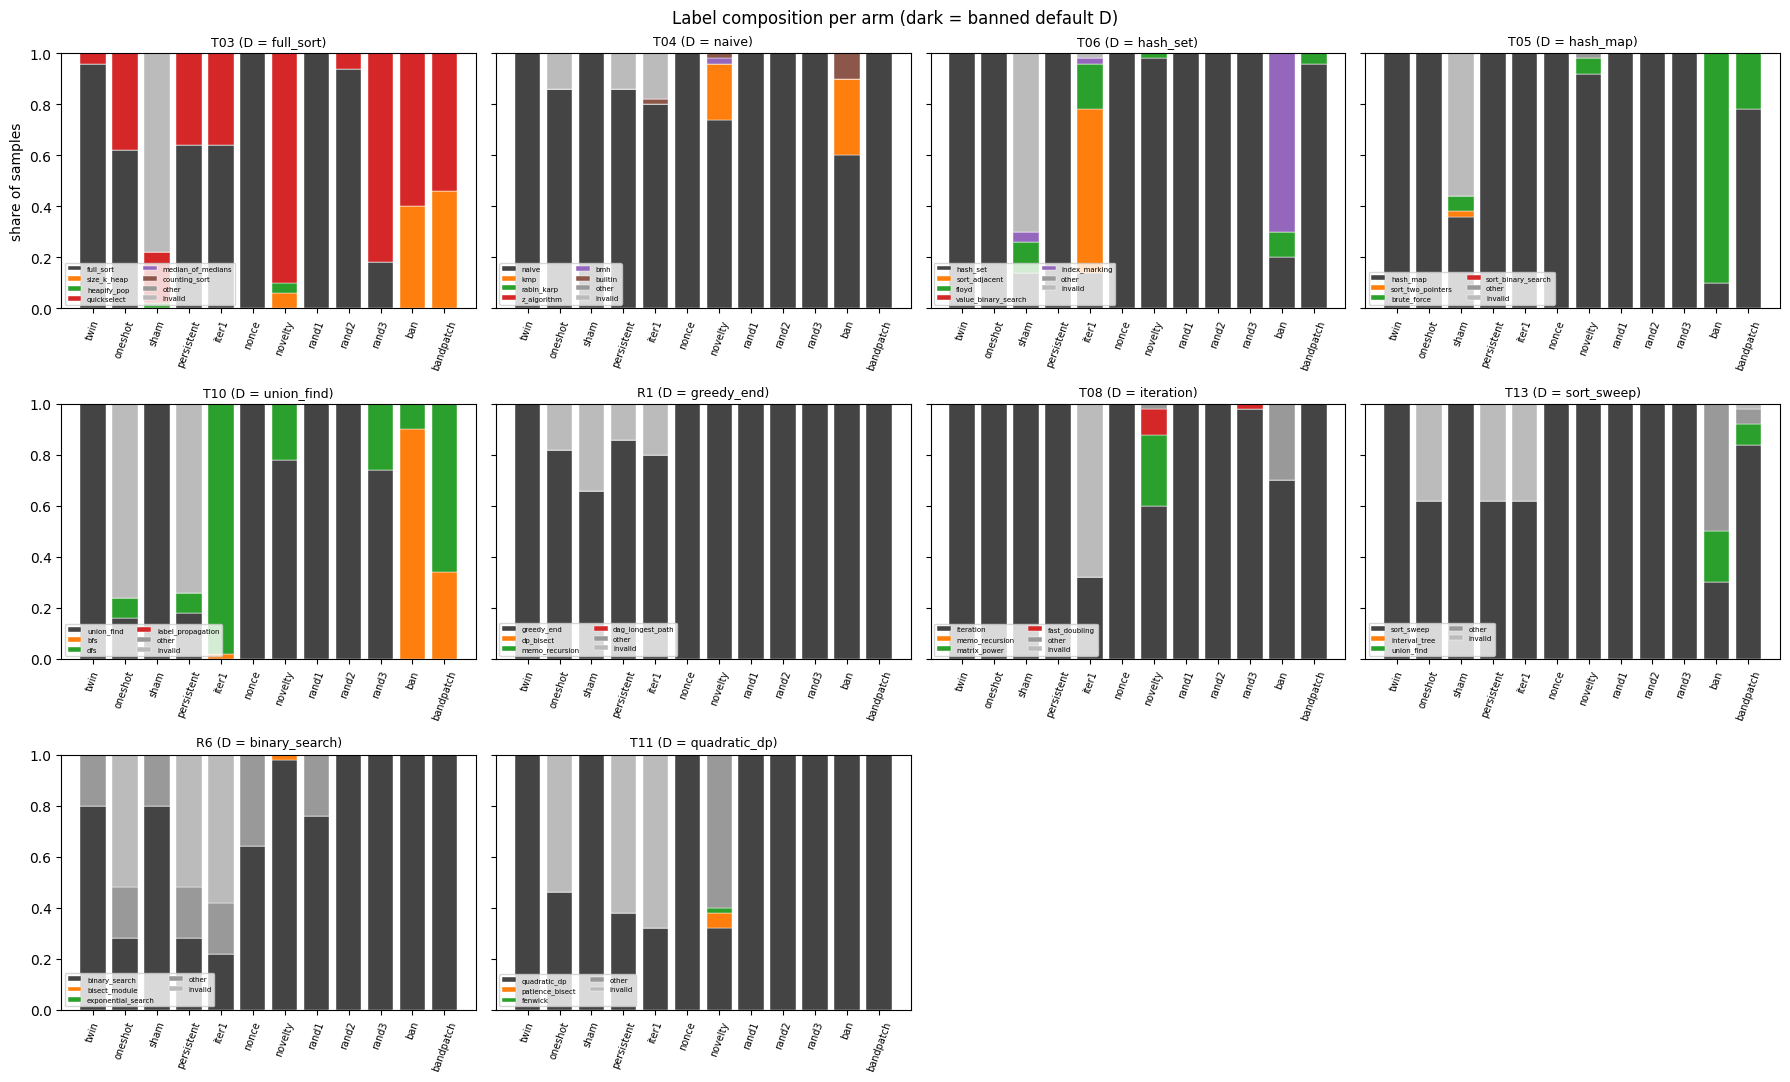

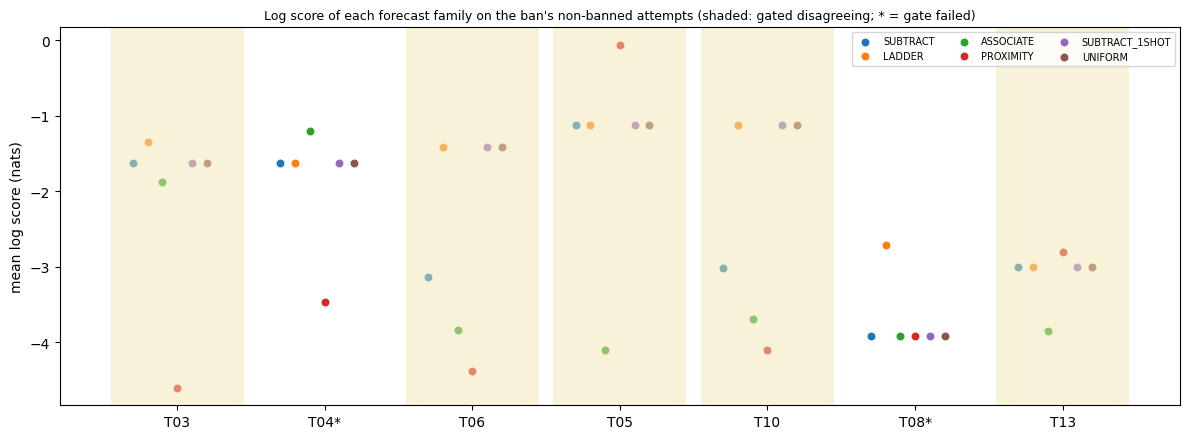

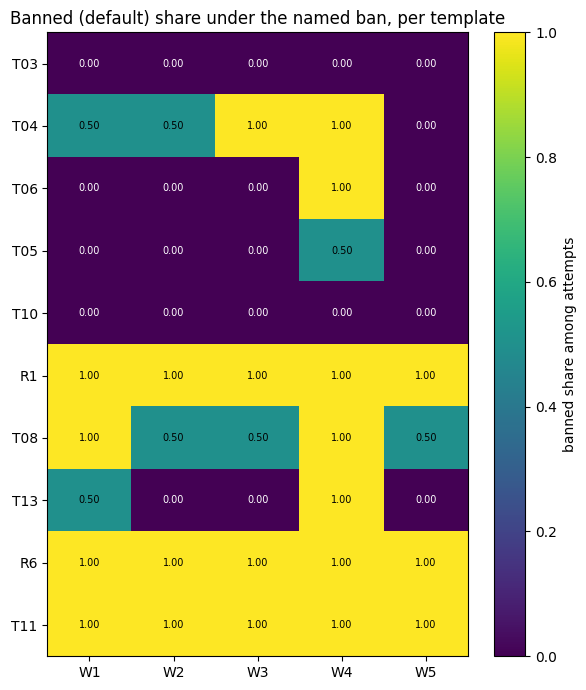

12:29:17|INFO   |C1 verdict: SUBTRACTION/LADDER (LADDER) | gated 5 disagreeing 5 | wins {'SUBTRACT': 0, 'LADDER': 3, 'ASSOCIATE': 0, 'PROXIMITY': 2}


12:29:17|INFO   |C2b verdict (one-shot): UNDETERMINED (eligible 0)


analysis done in 2.3s

task             D  n  avoidance  gate  n_non_banned                      landing realised top-1
 T03     full_sort 10        1.0  True            10 quickselect 6, size_k_heap 4    quickselect
 T04         naive 10        0.4 False             4             kmp 3, builtin 1            kmp
 T06      hash_set 10        0.8  True             8     index_marking 7, floyd 1  index_marking
 T05      hash_map 10        0.9  True             9                brute_force 9    brute_force
 T10    union_find 10        1.0  True            10                 bfs 9, dfs 1            bfs
  R1    greedy_end 10        0.0 False             0                                           -
 T08     iteration 10        0.3 False             3                      other 3          other
 T13    sort_sweep 10        0.7  True             7        other 5, union_find 2          other
  R6 binary_search 10        0.0 False             0                                           -
 T11  q

In [20]:
t_start = time.time()
analysis = run(store)
print(f"analysis done in {time.time() - t_start:.1f}s\n")

pd.set_option("display.width", 250)
ev_rows = [{"task": e["task"], "D": e["banned"], "n": e["n_samples"], "avoidance": round(e["avoidance"], 2),
            "gate": e["gate_pass"], "n_non_banned": e["n_non_banned"],
            "landing": ", ".join(f"{k} {v}" for k, v in sorted(e["landing_counts"].items(), key=lambda kv: -kv[1])),
            "realised top-1": "/".join(e["realised_top1"]) or "-"} for e in analysis["c1_events"]]
print(pd.DataFrame(ev_rows).to_string(index=False))

gated_rows = []
for e in analysis["c1_events"]:
    if e["gate_pass"]:
        gated_rows.append({"task": e["task"], **{f"{f} top-1": e["top1"][f] or "undefined" for f in PRIMARY},
                           **{f"LS {f}": round(e["logscore"][f], 2) for f in PRIMARY + ["UNIFORM"]}})
print("\ngated events: committed top-1s and log scores (nats)")
print(pd.DataFrame(gated_rows).to_string(index=False))

c1 = analysis["c1"]
print(f"\nC1 verdict (frozen rule): {c1['verdict']} | gated: {c1['gated_tasks']} | wins: {c1['advance']['wins']}")
print("winner per event:", [(x["task"], x["winner"]) for x in c1["advance"]["per_event"]],
      "| camp contest wins:", c1["camp_contest"]["wins"], "| gated events hit by no top-1:", c1["n_gated_no_family_hits"])
print("C2b verdicts:", {k: (v["verdict"], v["n_eligible"]) for k, v in analysis["c2b"].items() if isinstance(v, dict)})
for x in analysis["c2b"]["last_iterated"]["events"]:
    if x["eligible"]:
        print(f"  last iterated round on {x['task']} ({x['arm']}): veto modal {x['modal_veto']} vs ban modal "
              f"{x['modal_ban']}, JS {x['js']:.2f} vs null p95 {x['null_p95']:.2f}")
te = analysis["template_effect"]
print("template effect LR test:", {k: te["fixed_effects_lr"].get(k) for k in ("LR", "df", "p", "tasks_used")})
print("  placebo (templates shuffled within task):",
      {k: analysis["template_effect_placebo_shuffled"].get(k) for k in ("LR", "df", "p")})
print("  mixed GLM variance-component SDs (template, template x task):", te["mixed_glm"].get("sd_point"))
print("DISGUISE (share of banned-mechanism programs that never name D):",
      {t: v["share_disguised"] for t, v in analysis["descriptives"]["disguise"].items() if v["n_banned_mechanism"]})

## 9. `src/posthoc.py`: post-hoc sensitivity analyses (not pre-registered)

These were written after the bans were sampled. They do not replace the committed verdicts. They show what drives them:

1. **Defined-only advance.** A win counts only when the winning family's forecast is *defined*. The frozen rule scores an undefined forecast as uniform, so an undefined family can "win" an event on which every defined forecast missed. In the full run, this is how LADDER won T06 and T10.
2. **Every family against the UNIFORM reference**, as the mean log-score difference with a task-cluster bootstrap CI.
3. **The frozen rule re-run with UNIFORM as a fifth competitor.**
4. **The closest ban-free arm** to each gated ban landing, by JS divergence.

Changes from the original: `main` is renamed `posthoc_main`, because `method.py`'s `main` lives in the same namespace. The events come from the analysis above, and the bootstrap size comes from the config cell.

In [21]:
POSTHOC_DOC = """POST-HOC sensitivity analyses (NOT pre-registered; written after the bans were sampled and the committed analysis
was run).  They do not replace the committed verdicts; they show what drives them.

(1) defined-only advance: a win counts only when the winning family's forecast is defined (the frozen rule scores an
    undefined forecast as uniform, so an undefined family can 'win' an event on which every defined forecast missed);
(2) every family against the UNIFORM reference: events on which each family beats uniform by >= 0.10 nats, and the
    mean log-score difference with a task-cluster bootstrap CI;
(3) the frozen advance rule re-run with UNIFORM as a fifth competitor;
(4) ban-landing overlap with each arm (which ban-free arm's landing is closest to the ban's, by JS) per gated task.
"""

ARMS_CMP = ["oneshot", "persistent", "iter1", "iter2", "iter3", "nonce", "novelty", "rand1", "rand2", "rand3", "sham",
            "bandpatch"]


def posthoc_main(analysis: dict) -> dict[str, Any]:
    # notebook: posthoc.py main(); the events come from the analysis above (was results/c1_events.jsonl), the rows
    # from the notebook Store (was Store("")), and nothing is written to results/posthoc_sensitivity.json
    ev = analysis["c1_events"]
    gated = [e for e in ev if e["gate_pass"]]
    dis = [e for e in gated if e["disagreeing"]]
    cfg = FROZEN_CONSTANTS["advance"]
    out: dict[str, Any] = {"note": POSTHOC_DOC}
    # (1) defined-only wins
    wins = {f: 0 for f in PRIMARY}
    per = []
    for e in dis:
        w = None
        for f in PRIMARY:
            oth = [e["logscore"][g] for g in PRIMARY if g != f]
            if e["defined"][f] and e["logscore"][f] - max(oth) >= cfg["margin_nats"]:
                wins[f] += 1
                w = f
        per.append({"task": e["task"], "winner_defined_only": w,
                    "defined": {f: e["defined"][f] for f in PRIMARY}})
    out["defined_only_advance"] = {"wins": wins, "advancing": [f for f in PRIMARY if wins[f] >= cfg["min_wins"]],
                                   "per_event": per}
    # (2) vs uniform
    rng = np.random.default_rng(11)
    vs = {}
    for f in PRIMARY + ["SUBTRACT_1SHOT", "FRLP_FP8"]:
        d = np.array([e["logscore"][f] - e["logscore"]["UNIFORM"] for e in gated])
        # notebook: POSTHOC_N_BOOT bootstrap replicates (2000 in the original)
        boots = [float(np.mean(d[rng.integers(0, len(d), len(d))])) for _ in range(POSTHOC_N_BOOT)] if len(d) else []
        vs[f] = {"n_events": len(d), "n_beats_uniform_by_0.10": int(np.sum(d >= 0.10)),
                 "n_worse_than_uniform_by_0.10": int(np.sum(d <= -0.10)),
                 "mean_diff_vs_uniform": float(np.mean(d)) if len(d) else None,
                 "task_bootstrap_95": [float(np.quantile(boots, 0.025)), float(np.quantile(boots, 0.975))]
                 if boots else None,
                 "n_defined": sum(1 for e in gated if e["defined"][f])}
    out["vs_uniform_gated"] = vs
    # (3) frozen rule with UNIFORM as a competitor
    out["advance_with_uniform_competitor"] = advance(
        [{"task": e["task"], "logscore": {f: e["logscore"][f] for f in PRIMARY + ["UNIFORM"]}} for e in dis],
        PRIMARY + ["UNIFORM"], cfg["margin_nats"], cfg["min_wins"])
    # (4) closest ban-free arm landing to the ban landing
    st = store
    rand = st.lab_rows("rand")
    labs = {a: st.lab_rows(a) for a in ARMS_CMP if not a.startswith("rand")}
    for k in (1, 2, 3):
        labs[f"rand{k}"] = [r for r in rand if r.get("arm") == f"rand{k}"]
    close = {}
    for e in gated:
        t = e["task"]
        S = survivors(t)
        sp = S + ["other"]
        bl = Counter(e["landing_counts"])
        nb = sum(bl.values())
        pb = {k: bl.get(k, 0) / nb for k in sp}
        rows = {}
        for a, ls in labs.items():
            c = Counter((r["label"] if r["label"] in S else "other") for r in ls
                        if r["task"] == t and r["label"] not in ("invalid", DEFAULTS[t]))
            n = sum(c.values())
            if n >= 5:
                rows[a] = {"n_non_default": n, "js_to_ban": js_divergence({k: c.get(k, 0) / n for k in sp}, pb),
                           "modal": max(sp, key=lambda k: (c.get(k, 0), -sp.index(k)))}
        close[t] = {"ban_modal": e["realised_top1"], "arms": dict(sorted(rows.items(),
                                                                          key=lambda kv: kv[1]["js_to_ban"]))}
    out["closest_arm_to_ban_landing"] = close
    logger.info(f"post-hoc defined-only wins {wins}; vs uniform: " +
                ", ".join(f"{f}:{v['mean_diff_vs_uniform']:+.2f}" for f, v in vs.items()
                          if v["mean_diff_vs_uniform"] is not None))
    return out


ph = posthoc_main(analysis)
print("defined-only advance:", ph["defined_only_advance"]["wins"], "-> advancing:", ph["defined_only_advance"]["advancing"])
print("with UNIFORM as a competitor:", ph["advance_with_uniform_competitor"]["wins"])
for f, v in ph["vs_uniform_gated"].items():
    print(f"  {f:<15} mean LS - uniform {v['mean_diff_vs_uniform']:+.2f}  bootstrap 95% {np.round(v['task_bootstrap_95'], 2)}"
          f"  beats uniform on {v['n_beats_uniform_by_0.10']}/{v['n_events']}  (defined on {v['n_defined']})")
print("closest ban-free arm to each gated ban landing (JS, bits):")
for t, v in ph["closest_arm_to_ban_landing"].items():
    best = list(v["arms"].items())[:2]
    print(f"  {t}: ban modal {v['ban_modal']} | " + "; ".join(f"{a} JS {r['js_to_ban']:.2f} (modal {r['modal']})"
                                                         for a, r in best))

12:29:17|INFO   |post-hoc defined-only wins {'SUBTRACT': 0, 'LADDER': 1, 'ASSOCIATE': 0, 'PROXIMITY': 2}; vs uniform: SUBTRACT:-0.73, LADDER:+0.06, ASSOCIATE:-1.82, PROXIMITY:-1.53, SUBTRACT_1SHOT:+0.00, FRLP_FP8:-0.05


defined-only advance: {'SUBTRACT': 0, 'LADDER': 1, 'ASSOCIATE': 0, 'PROXIMITY': 2} -> advancing: []
with UNIFORM as a competitor: {'SUBTRACT': 0, 'LADDER': 1, 'ASSOCIATE': 0, 'PROXIMITY': 2, 'UNIFORM': 0}
  SUBTRACT        mean LS - uniform -0.73  bootstrap 95% [-1.49  0.  ]  beats uniform on 0/5  (defined on 2)
  LADDER          mean LS - uniform +0.06  bootstrap 95% [0.   0.17]  beats uniform on 1/5  (defined on 1)
  ASSOCIATE       mean LS - uniform -1.82  bootstrap 95% [-2.71 -0.81]  beats uniform on 0/5  (defined on 5)
  PROXIMITY       mean LS - uniform -1.53  bootstrap 95% [-2.98  0.08]  beats uniform on 2/5  (defined on 5)
  SUBTRACT_1SHOT  mean LS - uniform +0.00  bootstrap 95% [0. 0.]  beats uniform on 0/5  (defined on 0)
  FRLP_FP8        mean LS - uniform -0.05  bootstrap 95% [-0.15  0.  ]  beats uniform on 0/5  (defined on 1)
closest ban-free arm to each gated ban landing (JS, bits):
  T03: ban modal ['quickselect'] | bandpatch JS 0.00 (modal quickselect); novelty JS 0.14 

## 10. `src/figures_extra.py`: the extra figures

These are three figures drawn from the analysis outputs, with no new numbers:

1. **The log-score plot redrawn.** The shading is behind the points, and undefined forecasts are marked `x` because they are scored as uniform.
2. **The forecast-vs-realised table** for the gated events.
3. **Avoidance of every push vs the named ban**, per task. This heatmap shows how rarely the generic pushes and token vetoes move the model off its default, compared with the ban itself.

The inputs that the original reads from `results/c1_events.jsonl` and `results/analysis.json` are passed in as arguments. The figures are shown inline.

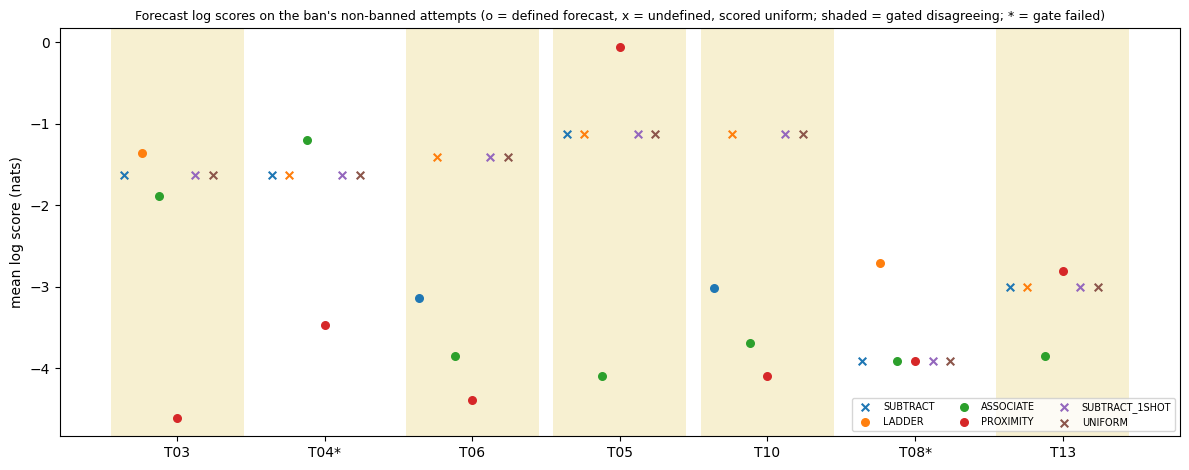

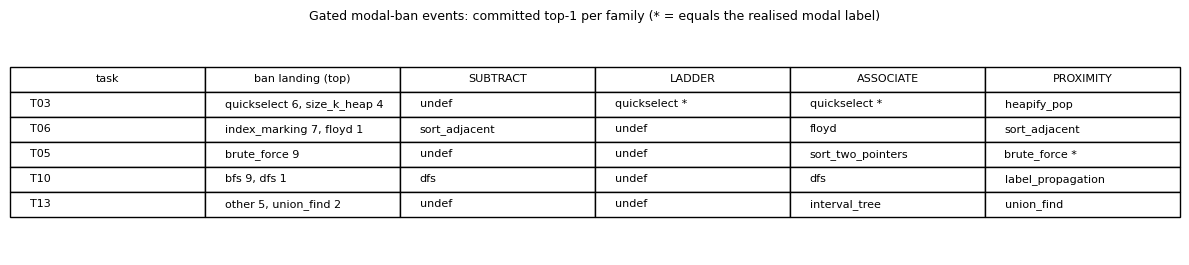

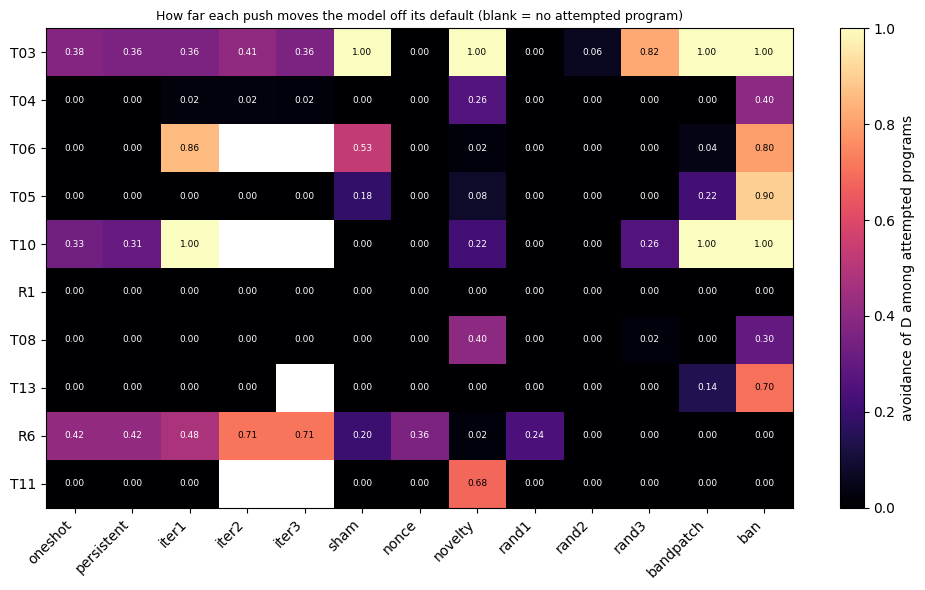

In [22]:
FAMS = ["SUBTRACT", "LADDER", "ASSOCIATE", "PROXIMITY", "SUBTRACT_1SHOT", "UNIFORM"]


def logscores(events: list[dict]) -> None:
    # notebook: events passed in (was read_jsonl(RESULTS / "c1_events.jsonl")); shown inline instead of saved
    ev = [e for e in events if e["n_non_banned"] > 0]
    fig, ax = plt.subplots(figsize=(12, 4.8))
    for i, e in enumerate(ev):
        if e["disagreeing"] and e["gate_pass"]:
            ax.axvspan(i - 0.45, i + 0.45, color="#f3e6b3", alpha=0.6, lw=0, zorder=0)
    mk = {True: "o", False: "x"}
    for j, f in enumerate(FAMS):
        xs = np.arange(len(ev)) + (j - len(FAMS) / 2) * 0.12
        for x, e in zip(xs, ev):
            ax.scatter(x, e["logscore"][f], color=plt.get_cmap("tab10")(j), marker=mk[bool(e["defined"][f])],
                       s=30, zorder=3, label=f if e is ev[0] else None)
    ax.set_xticks(range(len(ev)))
    ax.set_xticklabels([e["task"] + ("" if e["gate_pass"] else "*") for e in ev])
    ax.set_ylabel("mean log score (nats)")
    ax.set_title("Forecast log scores on the ban's non-banned attempts (o = defined forecast, x = undefined, scored "
                 "uniform; shaded = gated disagreeing; * = gate failed)", fontsize=9)
    ax.legend(fontsize=7, ncol=3, loc="lower right")
    fig.tight_layout()
    plt.show()


def forecast_table(events: list[dict]) -> None:
    # notebook: events passed in (was read_jsonl(RESULTS / "c1_events.jsonl")); shown inline instead of saved
    ev = [e for e in events if e["gate_pass"]]
    cols = ["task", "ban landing (top)", "SUBTRACT", "LADDER", "ASSOCIATE", "PROXIMITY"]
    cells = []
    for e in ev:
        land = sorted(e["landing_counts"].items(), key=lambda kv: -kv[1])
        top = ", ".join(f"{k} {v}" for k, v in land[:2])
        cells.append([e["task"], top] + [(e["top1"][f] or "undef") + (" *" if e["top1"][f] in e["realised_top1"]
                                                                        else "") for f in FAMS[:4]])
    fig, ax = plt.subplots(figsize=(12, 0.5 + 0.45 * len(cells)))
    ax.axis("off")
    t = ax.table(cellText=cells, colLabels=cols, loc="center", cellLoc="left")
    t.auto_set_font_size(False)
    t.set_fontsize(8)
    t.scale(1, 1.4)
    ax.set_title("Gated modal-ban events: committed top-1 per family (* = equals the realised modal label)",
                 fontsize=9)
    fig.tight_layout()
    plt.show()


def avoidance_heatmap(an: dict) -> None:
    # notebook: the analysis dict passed in (was read_json(RESULTS / "analysis.json")); shown inline instead of saved
    arms = ["oneshot", "persistent", "iter1", "iter2", "iter3", "sham", "nonce", "novelty", "rand1", "rand2", "rand3",
            "bandpatch", "ban"]
    pt = an["descriptives"]["per_task_arm"]
    M = np.full((len(TASK_ORDER), len(arms)), np.nan)
    for i, t in enumerate(TASK_ORDER):
        for j, a in enumerate(arms):
            v = pt.get(t, {}).get(a)
            if v and v.get("avoidance") is not None:
                M[i, j] = v["avoidance"]
    fig, ax = plt.subplots(figsize=(10, 6))
    im = ax.imshow(M, cmap="magma", vmin=0, vmax=1, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if not np.isnan(M[i, j]):
                ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=6.5,
                        color="white" if M[i, j] < 0.6 else "black")
    ax.set_xticks(range(len(arms)))
    ax.set_xticklabels(arms, rotation=45, ha="right")
    ax.set_yticks(range(len(TASK_ORDER)))
    ax.set_yticklabels(TASK_ORDER)
    fig.colorbar(im, ax=ax, label="avoidance of D among attempted programs")
    ax.set_title("How far each push moves the model off its default (blank = no attempted program)", fontsize=9)
    fig.tight_layout()
    plt.show()


logscores(analysis["c1_events"])
forecast_table(analysis["c1_events"])
avoidance_heatmap(analysis)

## 11. Results: the demo subset next to the stored full run

The tables put the demo-scale numbers (`5 × N_PER_CELL` ban samples per task) next to the full run's committed results (100 per task), which are stored in the mini file. The three panels show:

- **(a) Does the named ban move the model off D?** Ban avoidance per task with Wilson intervals; the dashed line is the 0.5 gate.
- **(b) Does any ban-free forecast beat chance?** Each family's mean log score minus the uniform reference over gated events. Undefined forecasts score exactly uniform. LADDER's small +0.06 comes from its single defined forecast (T03, quickselect). The point-forecast families pay heavily whenever their nominee misses.
- **(c) How far does the ban push the hidden states?** The mean displacement ‖h(ban) − h(twin)‖ of the task-spec hidden states at decoder layers 12-23 (process B, `results/norms_summary.json`). The 3 isotropic random directions of the LADDER arm were matched to this norm.

task             D  demo n  demo avoid  demo gate                 demo landing  full n  full avoid  full gate                   full landing
 T03     full_sort      10         1.0       True quickselect 6, size_k_heap 4     100        0.97       True quickselect 59, size_k_heap 38
 T04         naive      10         0.4      False             kmp 3, builtin 1     100        0.40      False             kmp 21, builtin 16
 T06      hash_set      10         0.8       True     index_marking 7, floyd 1     100        0.79       True      index_marking 73, floyd 5
 T05      hash_map      10         0.9       True                brute_force 9     100        0.86       True                 brute_force 86
 T10    union_find      10         1.0       True                 bfs 9, dfs 1     100        1.00       True                 bfs 83, dfs 17
  R1    greedy_end      10         0.0      False                            -     100        0.00      False                              -
 T08     iter

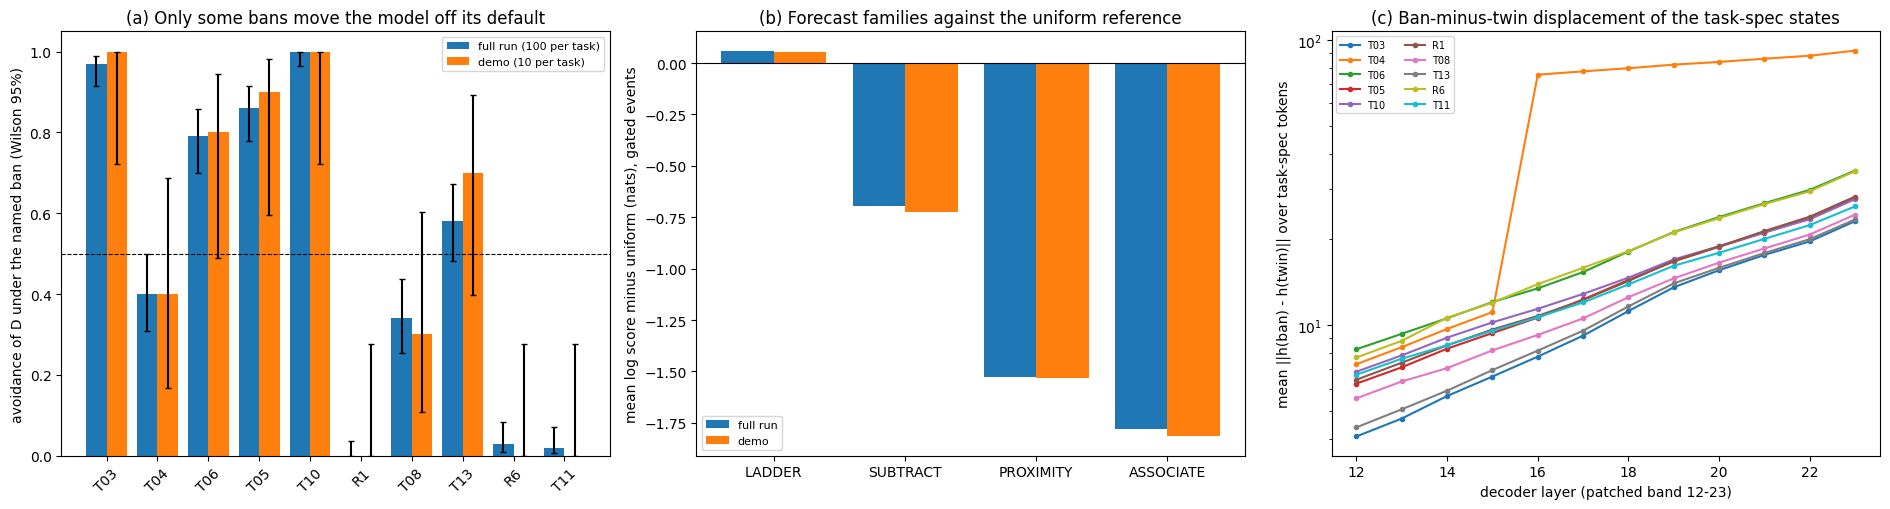

In [23]:
# ---- demo scale vs the stored full run ----
full = meta["full_run"]
full_ev = {e["task"]: e for e in full["c1_events"]}
demo_ev = {e["task"]: e for e in analysis["c1_events"]}
fams4 = ["LADDER", "SUBTRACT", "PROXIMITY", "ASSOCIATE"]


def _land(lc: dict) -> str:
    return ", ".join(f"{k} {v}" for k, v in sorted(lc.items(), key=lambda kv: -kv[1])[:2]) or "-"


def _lr(d: dict) -> str:
    return f"LR {d['LR']:.1f} (df {d['df']}), p {d['p']:.2g}" if d.get("defined") else "undefined"


per_task = pd.DataFrame([{"task": t, "D": DEFAULTS[t],
                          "demo n": demo_ev[t]["n_samples"], "demo avoid": round(demo_ev[t]["avoidance"], 2),
                          "demo gate": demo_ev[t]["gate_pass"], "demo landing": _land(demo_ev[t]["landing_counts"]),
                          "full n": full_ev[t]["n_samples"], "full avoid": round(full_ev[t]["avoidance"], 2),
                          "full gate": full_ev[t]["gate_pass"], "full landing": _land(full_ev[t]["landing_counts"])}
                         for t in TASK_ORDER])
print(per_task.to_string(index=False))

c1f = full["c1"]
summary = pd.DataFrame({
    f"demo ({5 * N_PER_CELL} ban samples / task)": {
        "gated tasks": ", ".join(analysis["c1"]["gated_tasks"]),
        "C1 verdict (frozen rule)": analysis["c1"]["verdict"],
        "C1 wins": str(analysis["c1"]["advance"]["wins"]),
        "post-hoc defined-only wins": str(ph["defined_only_advance"]["wins"]),
        **{f"mean LS - uniform: {f}": f"{ph['vs_uniform_gated'][f]['mean_diff_vs_uniform']:+.2f}" for f in fams4},
        "C2b verdict (one-shot)": analysis["c2b"]["oneshot"]["verdict"],
        "template effect": _lr(analysis["template_effect"]["fixed_effects_lr"]),
        "template placebo": _lr(analysis["template_effect_placebo_shuffled"])},
    "full run (stored, 100 / task)": {
        "gated tasks": ", ".join(c1f["gated_tasks"]),
        "C1 verdict (frozen rule)": c1f["verdict"],
        "C1 wins": str(c1f["advance"]["wins"]),
        "post-hoc defined-only wins": str(full["posthoc"]["defined_only_advance"]["wins"]),
        **{f"mean LS - uniform: {f}": f"{full['posthoc']['vs_uniform_gated'][f]['mean_diff_vs_uniform']:+.2f}"
           for f in fams4},
        "C2b verdict (one-shot)": full["c2b"]["oneshot"]["verdict"],
        "template effect": _lr(full["template_effect"]["fixed_effects_lr"]),
        "template placebo": _lr(full["template_effect"]["placebo_template_shuffled"])}})
print()
print(summary.to_string())
print(f"\nfull run only (needs the raw veto texts): D re-emerges in every veto round on "
      f"{full['reemergence_share_tasks_default_in_every_round']:.0%} of tasks; one-shot veto fire rate "
      f"{full['veto']['oneshot']['fire_rate']:.2f}; vetoed n-gram leaks back as text in "
      f"{full['veto']['oneshot']['text_leak_rate']:.0%} of one-shot and {full['veto']['iter2']['text_leak_rate']:.0%} "
      f"of round-2 samples")

fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
x = np.arange(len(TASK_ORDER))
for off, src, lab in [(-0.2, full_ev, "full run (100 per task)"), (0.2, demo_ev, f"demo ({5 * N_PER_CELL} per task)")]:
    av = np.array([src[t]["avoidance"] for t in TASK_ORDER])
    lo = np.array([src[t]["avoidance_wilson95"][0] for t in TASK_ORDER])
    hi = np.array([src[t]["avoidance_wilson95"][1] for t in TASK_ORDER])
    # clip: at avoidance 0 or 1 the Wilson bound can sit a rounding error past the point estimate
    axes[0].bar(x + off, av, 0.4, yerr=[np.clip(av - lo, 0, None), np.clip(hi - av, 0, None)], capsize=2, label=lab)
axes[0].axhline(FROZEN_CONSTANTS["gate"]["min_avoidance"], color="k", ls="--", lw=0.8)
axes[0].set_xticks(x)
axes[0].set_xticklabels(TASK_ORDER, rotation=45)
axes[0].set_ylabel("avoidance of D under the named ban (Wilson 95%)")
axes[0].set_title("(a) Only some bans move the model off its default")
axes[0].legend(fontsize=8)

xf = np.arange(len(fams4))
axes[1].bar(xf - 0.2, [full["posthoc"]["vs_uniform_gated"][f]["mean_diff_vs_uniform"] for f in fams4], 0.4,
            label="full run")
axes[1].bar(xf + 0.2, [ph["vs_uniform_gated"][f]["mean_diff_vs_uniform"] for f in fams4], 0.4, label="demo")
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_xticks(xf)
axes[1].set_xticklabels(fams4)
axes[1].set_ylabel("mean log score minus uniform (nats), gated events")
axes[1].set_title("(b) Forecast families against the uniform reference")
axes[1].legend(fontsize=8)

for t in TASK_ORDER:
    axes[2].plot(BAND, meta["norms_summary"][t]["mean_norm_per_layer"], marker="o", ms=3, label=t)
axes[2].set_yscale("log")
axes[2].set_xlabel("decoder layer (patched band 12-23)")
axes[2].set_ylabel("mean ||h(ban) - h(twin)|| over task-spec tokens")
axes[2].set_title("(c) Ban-minus-twin displacement of the task-spec states")
axes[2].legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()

## What the numbers say

**Bans often fail on this collapsed model.** In the full run, only 5 of 12 modal bans pass the gate. R1, R3, R6 and T11 keep their default on almost every sample, whatever the wording. The wording itself matters a lot. The template LR is 374 in the full run and already about 28 (p ≈ 1e-5) on the 10-sample demo subset, while the shuffled-template placebo stays null. Under W4 ("X is not allowed here.") the default survives on 10 of 12 tasks.

**Where gated bans land is mostly unforeseen.**
- T06 goes to `index_marking`, a mode no family nominated.
- T10 goes to BFS, while SUBTRACT and ASSOCIATE said DFS.
- T13 goes mostly to "other": a merge sweep without sorting, which fails its tests.
- Only T03 (quickselect) and T05 (brute force) are hit by a top-1.

**The C1 verdict leans on undefined forecasts.** The frozen rule's `SUBTRACTION/LADDER (LADDER)` rests on two "wins" by an undefined LADDER forecast scored as uniform. Counting defined forecasts only, no family advances. The demo subset (10 of the 100 ban samples per task) reproduces each of these results:

| result | demo subset (10 per task) | full run |
|---|---|---|
| gated tasks | same 5 | 5 |
| frozen-rule wins | LADDER 3, PROXIMITY 2 | LADDER 3, PROXIMITY 2 |
| defined-only wins | LADDER 1, PROXIMITY 2 | LADDER 1, PROXIMITY 2 |
| mean log score minus uniform | +0.06 / −0.73 / −1.53 / −1.82 | +0.06 / −0.69 / −1.53 / −1.78 |

**Token vetoes move the surface, not the algorithm.** The model re-spells the same mechanism instead of changing it: `' complement'` becomes `' compliment'`, and `nums.sort()` becomes `sorted(nums)[k-1]`. The vetoed text leaks back in 23-54% of samples, and D re-emerges in every veto round on 9 of 12 tasks.

**Caveats.** One model, memorised LeetCode-style tasks, and 5 gated events: the analysis gives an advance count, not a significance test.

**Scaling back to the full run.**
1. Build the full-size input with `python build_mini_demo_data.py --artifact-dir <artifact folder> --per-cell 20 --tasks all --out full_demo_data.json`.
2. Load it in place of the mini file.
3. Set `TASKS` to all 12 tasks and `N_PER_CELL = 20`.

The analysis cells then reproduce the artifact's committed CPU analysis (`python method.py analyze posthoc` in the artifact folder) number for number. The GPU stages (`gen_a`, `hf_b`, `gen_c`, `hf_d`, `frlp`) regenerate the samples themselves. They need Qwen3-8B at revision `b968826d` and a ≥ 24 GB GPU (about 45 minutes on an RTX 4090), plus OpenRouter judge credentials for label disagreements.